# Đồ án giữa kỳ: Nhận dạng chữ số viết tay MNIST bằng bốn phương pháp phân lớp

Notebook trình bày quy trình tiền xử lý, cài đặt và đánh giá bốn phương pháp phân lớp trên bộ dữ liệu MNIST. Các bảng số liệu và hình ảnh được tạo từ các cell thực nghiệm; phần nhận xét diễn giải kết quả của lần chạy được lưu trong Notebook.

**Nguồn mã duy nhất để tái lập thực nghiệm:** `mnist_colab_source.zip`. Các file trong `src/` và `tests/` được lấy từ gói mã nguồn này.


## Hướng dẫn thực thi trên Google Colab

**Chuẩn bị:** Tải `mnist_colab_source.zip` lên thư mục gốc **My Drive** của Google Drive. Gói ZIP phải chứa `src/`, `tests/` và các file cấu hình cần thiết ở cùng cấp thư mục dự án. Notebook sử dụng mã nguồn trong gói ZIP này để thực hiện toàn bộ thí nghiệm.

**Trình tự:** Kết nối runtime, chạy hai cell thiết lập, sau đó chạy các cell nhập thư viện, tải dữ liệu và thực nghiệm theo thứ tự. Không khởi chạy đồng thời nhiều lượt thực thi Notebook.

**Tiếp tục phiên chạy:** Các lần `fit()` hoàn tất và được lưu thành công trong `artifacts/cache/` nằm dưới thư mục kết quả (`OUTPUT_ROOT`) có thể được tái sử dụng nếu mã nguồn, dữ liệu, cấu hình và môi trường tương thích không đổi. Một lần huấn luyện bị ngắt trước khi lưu checkpoint cần được chạy lại. Thời gian huấn luyện được báo cáo là thời gian ghi nhận khi huấn luyện thực tế, không phải thời gian tải checkpoint.

**Thiết bị thực thi:** Các phép tính của MLP hiện sử dụng CPU; chỉ chọn bộ tăng tốc GPU trên Colab không làm thay đổi thiết bị xử lý của mô hình. Để so sánh nhất quán, giữ nguyên quy mô dữ liệu và các tham số thí nghiệm.

**Thư mục kết quả:** Trên Colab, `results/`, `figures/` và `artifacts/` nằm trong thư mục kết quả trên Google Drive do cell thiết lập tạo ra. Đường dẫn thực tế được in qua biến `OUTPUT_ROOT` và toàn bộ kết quả đầu ra sẽ được lưu trữ đồng bộ tại đây.

In [15]:
import hashlib
import os
import sys
import zipfile
from pathlib import Path

try:
  import google.colab
  IN_COLAB = True
except ImportError:
  IN_COLAB = False

ZIP_NAME = "mnist_colab_source.zip"
RUN_NAME = "v1_3_seed42"


def is_project_root(folder):
  return ((folder / "src" / "dataset.py").is_file()
          and (folder / "src" / "models" / "mlp.py").is_file()
          and (folder / "tests" / "test_models.py").is_file())


if IN_COLAB:
  from google.colab import drive
  drive.mount("/content/drive")
  zip_path = Path("/content/drive/MyDrive") / ZIP_NAME
  if not zip_path.is_file():
    raise FileNotFoundError(
        f"Chưa tìm thấy {zip_path}. Hãy tải {ZIP_NAME} lên My Drive trước."
        )

  # Mỗi phiên bản ZIP được giải nén vào một thư mục riêng, không xóa dữ liệu cũ.
  zip_hash = hashlib.sha256(zip_path.read_bytes()).hexdigest()[:12]
  unpack_dir = Path("/content") / f"mnist_v1_3_source_{zip_hash}"
  marker = unpack_dir / ".extraction_complete"
  if not marker.exists():
    unpack_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
      # Không cho phép ZIP chứa đường dẫn đi ra ngoài thư mục giải nén.
      for item in archive.infolist():
        dest = (unpack_dir / item.filename).resolve()
        if not dest.is_relative_to(unpack_dir.resolve()):
          raise ValueError(f"Đường dẫn không an toàn trong ZIP: {item.filename}")
      archive.extractall(unpack_dir)
    marker.touch()

  candidates = [unpack_dir, *[p for p in unpack_dir.iterdir() if p.is_dir()]]
  matches = [p for p in candidates if is_project_root(p)]
  if len(matches) != 1:
    raise RuntimeError(
        "Không xác định được duy nhất project root trong ZIP. "
        "ZIP cần chứa src/, tests/ và requirements.txt tại cùng một cấp."
        )
  PROJECT_ROOT = matches[0].resolve()
else:
  current = Path.cwd().resolve()
  matches = [p for p in (current, *current.parents) if is_project_root(p)]
  if not matches:
    raise FileNotFoundError(
        "Local: hãy mở Notebook từ project root hoặc thư mục notebooks/ "
        "(phải có src/ và tests/)."
        )
  PROJECT_ROOT = matches[0]

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
  sys.path.insert(0, str(PROJECT_ROOT))

# Fingerprint nguồn: cache không bị dùng lại nếu thay code thuật toán / dataset.
SOURCE_FILES = [
  "src/dataset.py", "src/metrics.py",
  "src/models/naive_bayes.py", "src/models/softmax_regression.py",
  "src/models/mlp.py", "src/models/ensemble.py",
]
source_hasher = hashlib.sha256()
for relative in SOURCE_FILES:
  file_path = PROJECT_ROOT / relative
  if not file_path.is_file():
    raise FileNotFoundError(f"Thiếu mã nguồn: {file_path}")
  source_hasher.update(relative.encode("utf-8"))
  source_hasher.update(file_path.read_bytes())
SOURCE_FINGERPRINT = source_hasher.hexdigest()[:16]

if IN_COLAB:
  OUTPUT_ROOT = (Path("/content/drive/MyDrive/MNIST_v1_3_outputs")
                / f"{RUN_NAME}_{SOURCE_FINGERPRINT}")
else:
  OUTPUT_ROOT = PROJECT_ROOT

print("Môi trường:", "Google Colab" if IN_COLAB else "Local")
print("PROJECT_ROOT:", PROJECT_ROOT)
print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("Mã nguồn    :", SOURCE_FINGERPRINT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Môi trường: Google Colab
PROJECT_ROOT: /content/mnist_v1_3_source_8af82b05e98f
OUTPUT_ROOT : /content/drive/MyDrive/MNIST_v1_3_outputs/v1_3_seed42_1ee5ec53dd27a11b
Mã nguồn    : 1ee5ec53dd27a11b


In [16]:
# CELL 1 — Cài các thư viện thiếu trên Colab, không tự thay đổi môi trường Local.
import importlib.util
import subprocess
import sys

required = {
  "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
  "sklearn": "scikit-learn", "torch": "torch", "torchvision": "torchvision",
  "joblib": "joblib", "pytest": "pytest",
}
missing = [package for module, package in required.items()
          if importlib.util.find_spec(module) is None]
if missing:
  if not IN_COLAB:
    raise RuntimeError("Local thiếu thư viện: " + ", ".join(missing)
                      + ". Hãy cài bằng môi trường ảo hiện tại.")
  print("Đang cài thư viện thiếu:", missing)
  subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
else:
  print("Các thư viện cần thiết đã có sẵn.")

assert (PROJECT_ROOT / "src" / "models" / "ensemble.py").is_file()
assert (PROJECT_ROOT / "tests" / "test_models.py").is_file()
print("Kiểm tra cấu trúc project: OK")

Các thư viện cần thiết đã có sẵn.
Kiểm tra cấu trúc project: OK


# 1. Giới thiệu và thiết lập môi trường

## 1.1 Mục tiêu và phạm vi

Mục tiêu của thực nghiệm là xây dựng, điều chỉnh siêu tham số và so sánh bốn phương pháp phân lớp trên MNIST. Phần cài đặt nằm trong `src/models/` của gói `mnist_colab_source.zip`.

| Phương pháp | Thành phần do nhóm cài đặt | Thư viện hỗ trợ |
|---|---|---|
| Multinomial Naive Bayes | Ước lượng xác suất tiên nghiệm, tổng cường độ pixel theo lớp, làm mịn Laplace và tính điểm log-xác suất | NumPy |
| Softmax Regression | Hàm Softmax, Cross-Entropy, gradient, mini-batch SGD và điều chuẩn L2 | NumPy |
| MLP | Lan truyền xuôi, lan truyền ngược, SGD kết hợp Momentum, Inverted Dropout, L2 và Early Stopping | PyTorch cung cấp tensor, phép toán và các lớp tuyến tính; không dùng `loss.backward()` hoặc `torch.optim` để huấn luyện |
| Random Forest | Lấy mẫu bootstrap, tổ chức tập hợp cây và biểu quyết đa số | `sklearn.tree.DecisionTreeClassifier` làm cây cơ sở |

**Phạm vi tự cài đặt:** Random Forest tự triển khai cơ chế bagging (bootstrap) và biểu quyết đa số, nhưng **không tự cài đặt thuật toán xây dựng cây quyết định**; cây cơ sở là `sklearn.tree.DecisionTreeClassifier`. Phương án này đã được giảng viên chấp thuận.

Các ký hiệu E1–E5 (khảo sát dữ liệu), P1–P4 (minh họa phương pháp), N1/S1–S3/M0–M7/R1–R3 (thí nghiệm theo mô hình) và K1–K5 (đánh giá, đối chiếu) dùng để tham chiếu các bảng, hình trong Notebook.

**Quy tắc phân chia dữ liệu:** Tập train dùng để huấn luyện, validation dùng để lựa chọn siêu tham số và Early Stopping, còn tập test chỉ được dùng trong phần đánh giá cuối và đối chiếu thư viện.


In [17]:
import json
import math
import os
import platform
import subprocess
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from matplotlib.patches import FancyBboxPatch
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

assert (PROJECT_ROOT / "src" / "dataset.py").is_file(), PROJECT_ROOT
if str(PROJECT_ROOT) not in sys.path:
  sys.path.insert(0, str(PROJECT_ROOT))

from src.models.naive_bayes import NaiveBayes
from src.models.softmax_regression import SoftmaxRegression
from src.models.mlp import MLPFromScratch, forward_with_cache, softmax_cross_entropy
from src.models.ensemble import RandomForestFromScratch
from src.dataset import load_and_preprocess_mnist
from src.metrics import compute_classification_metrics

SEED = 42

print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("PyTorch     :", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__)
print("CUDA khả dụng:", torch.cuda.is_available(), "| số luồng CPU của PyTorch:", torch.get_num_threads())
print("PROJECT_ROOT:", PROJECT_ROOT)

Python      : 3.13.18
NumPy       : 2.4.6
PyTorch     : 2.14.1+cpu
scikit-learn: 1.6.1
pandas      : 2.2.3
CUDA khả dụng: False | số luồng CPU của PyTorch: 1
PROJECT_ROOT: /content/mnist_v1_3_source_8af82b05e98f


In [18]:
DATA_DIR = PROJECT_ROOT / "data"  # MNIST raw/cache trên ổ tạm của Colab
FIG_DIR = OUTPUT_ROOT / "figures"
RESULT_DIR = OUTPUT_ROOT / "results"
ARTIFACT_DIR = OUTPUT_ROOT / "artifacts"
CACHE_DIR = ARTIFACT_DIR / "cache"
for directory in (DATA_DIR, FIG_DIR, RESULT_DIR, ARTIFACT_DIR, CACHE_DIR):
  directory.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.grid": False})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", None)


def set_seed(seed=SEED):
  np.random.seed(seed)
  torch.manual_seed(seed)

def save_figure(fig, name):
  fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
  plt.show()

def save_table(df, name, index=False):
  df.to_csv(RESULT_DIR / f"{name}.csv", index=index)
  return df

set_seed()

### 1.2 Môi trường thực nghiệm

Các thông số dưới đây được ghi nhận từ lần chạy Colab đang lưu trong Notebook:

- **Nền tảng:** Google Colab, Linux, Python 3.13.18.
- **Thư viện:** NumPy 2.4.6, PyTorch 2.11.0+cpu, scikit-learn 1.6.1, pandas 2.2.3.
- **Thiết bị:** CPU ảo của môi trường Colab; `torch.cuda.is_available()` trả về `False` tại thời điểm chạy.


# 2. Dữ liệu MNIST và tiền xử lý

## 2.1 Tải dữ liệu và chia tập

Hàm `load_and_preprocess_mnist` đọc 60.000 ảnh train và 10.000 ảnh test gốc của MNIST. Ảnh `28 × 28` được chuyển thành vector 784 chiều, sau đó cường độ pixel được chia cho 255 để đưa về khoảng [0, 1].

Từ tập train gốc, 50.000 ảnh được dùng để huấn luyện và 10.000 ảnh để validation, với `seed=42`. Tập test gốc được giữ nguyên.


In [19]:
X_train, y_train, X_val, y_val, X_test, y_test = load_and_preprocess_mnist(data_dir=str(DATA_DIR))
SPLIT_NAMES = ["train", "validation", "test"]
SPLITS = {"train": (X_train, y_train), "validation": (X_val, y_val), "test": (X_test, y_test)}

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.83MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 153kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.03MB/s]


### Lưu và tái sử dụng kết quả huấn luyện

Hàm `fit_model_cached()` lưu trạng thái mô hình sau khi một lần huấn luyện hoàn tất. Nếu mã nguồn, dữ liệu, siêu tham số và phiên bản thư viện tương thích, checkpoint được nạp để tránh lặp lại lần `fit()` đó. Cơ chế này không lưu tiến độ giữa các epoch. File cache sử dụng định dạng `joblib`/pickle; chỉ nạp các checkpoint từ nguồn tin cậy. Các giá trị thời gian trong bảng phản ánh lần huấn luyện ban đầu.


In [20]:
# CELL — Hỗ trợ cache theo từng lần fit; không chỉnh thuật toán trong src/models/.
import hashlib
import json
import os
import platform
import time
from pathlib import Path

# Giữ True để tiếp tục sau khi Colab ngắt kết nối. Đổi False để train lại từ đầu.
USE_FIT_CACHE = True

DATA_FINGERPRINT = hashlib.sha256(
  X_train[:32].tobytes() + y_train[:128].tobytes()
  + X_val[:32].tobytes() + y_val[:128].tobytes()
).hexdigest()[:16]


def model_config_for_cache(model):
  if hasattr(model, "get_params"):
    return model.get_params(deep=False)
  if isinstance(model, NaiveBayes):
    return {"alpha": model.alpha}
  if isinstance(model, SoftmaxRegression):
    return {k: getattr(model, k) for k in
            ("lr", "max_epochs", "batch_size", "lam", "seed")}
  if isinstance(model, MLPFromScratch):
    return {k: getattr(model, k) for k in
            ("sizes", "lr", "momentum", "max_epochs", "batch_size",
              "dropout", "weight_decay", "patience", "seed", "eval_batch_size")}
  if isinstance(model, RandomForestFromScratch):
    return {k: getattr(model, k) for k in
            ("n_estimators", "max_depth", "max_features", "seed")}
  raise TypeError(f"Chưa hỗ trợ cache cho model: {type(model).__name__}")


def fit_model_cached(model, fit_args, tag="experiment"):
  # Không thay đổi cách fit; chỉ bỏ qua fit nếu checkpoint hợp lệ tồn tại.
  import joblib
  import sklearn
  import torch

  spec = {
      "tag": tag,
      "model_class": f"{type(model).__module__}.{type(model).__name__}",
      "params": model_config_for_cache(model),
      "source": SOURCE_FINGERPRINT,
      "data": DATA_FINGERPRINT,
      "fit_shapes": [list(a.shape) if hasattr(a, "shape") else len(a)
                    for a in fit_args],
      "python": platform.python_version(),
      "numpy": np.__version__,
      "sklearn": sklearn.__version__,
      "torch": torch.__version__,
      }
  signature = hashlib.sha256(json.dumps(
      spec, sort_keys=True, ensure_ascii=False, default=str
  ).encode("utf-8")).hexdigest()[:24]
  path = CACHE_DIR / f"{type(model).__name__}_{signature}.joblib"

  if USE_FIT_CACHE and path.is_file():
    try:
      record = joblib.load(path)
      if record.get("signature") == signature:
        # Giữ nguyên object được dùng ở các cell tiếp theo.
        model.__dict__.clear()
        model.__dict__.update(record["model"].__dict__)
        model._colab_cache_hit = True
        print(f"[CACHE HIT] {type(model).__name__} / {tag}")
        return float(record["fit_time_s"])
    except Exception as exc:
      print(f"[CACHE INVALID] {path.name}: {exc}. Sẽ train lại.")

  start = time.perf_counter()
  model.fit(*fit_args)
  elapsed = time.perf_counter() - start
  model._colab_cache_hit = False

  # Không lưu checkpoint bị phân kỳ.
  if USE_FIT_CACHE and not bool(getattr(model, "diverged_", False)):
    record = {"signature": signature, "fit_time_s": elapsed, "model": model}
    tmp = path.with_name(path.name + ".partial")
    try:
      joblib.dump(record, tmp, compress=3)
      os.replace(tmp, path)
      print(f"[CACHE SAVED] {type(model).__name__} / {tag} ({elapsed:.1f}s)")
    except Exception as exc:
      print(f"[CACHE WARNING] Không lưu được {path.name}: {exc}")
      if tmp.exists():
        tmp.unlink()
  return elapsed

print("DATA_FINGERPRINT:", DATA_FINGERPRINT)
print("Checkpoint folder:", CACHE_DIR)

DATA_FINGERPRINT: f966d5327d91d125
Checkpoint folder: /content/drive/MyDrive/MNIST_v1_3_outputs/v1_3_seed42_1ee5ec53dd27a11b/artifacts/cache


## 2.2 Kích thước dữ liệu và ảnh minh họa

In [21]:
df_split = pd.DataFrame([
    {"split": name, "n_samples": len(X), "n_features": X.shape[1], "image_shape": "28x28",
     "n_classes": len(np.unique(y)), "dtype": str(X.dtype),
     "pixel_min": float(X.min()), "pixel_max": float(X.max())}
    for name, (X, y) in SPLITS.items()
])
save_table(df_split, "data_split_summary")

,split,n_samples,n_features,image_shape,n_classes,dtype,pixel_min,pixel_max
0,train,50000,784,28x28,10,float32,0.0000,1.0000
1,validation,10000,784,28x28,10,float32,0.0000,1.0000
2,test,10000,784,28x28,10,float32,0.0000,1.0000


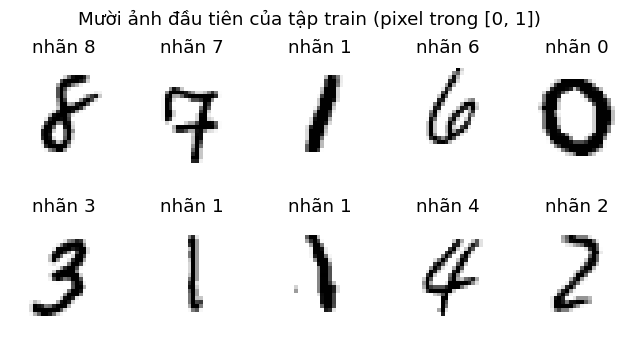

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.8))
for ax, img, label in zip(axes.ravel(), X_train[:10], y_train[:10]):
  ax.imshow(img.reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
  ax.set_title(f"nhãn {label}")
  ax.axis("off")

fig.suptitle("Mười ảnh đầu tiên của tập train (pixel trong [0, 1])")
save_figure(fig, "data_samples")

## 2.3 Dữ liệu đầu vào của từng model

Cả bốn model dùng cùng pixel trong `[0, 1]`. Multinomial Naive Bayes yêu cầu đặc trưng không âm nên không áp dụng z-score. Không có bước chuẩn hóa nào được fit trên validation hoặc test.

In [23]:
MODEL_NAMES = ["Naive Bayes", "Softmax Regression", "MLP", "Random Forest"]
FEATURES = {name: (X_train, X_val, X_test) for name in MODEL_NAMES}
LABELS = (y_train, y_val, y_test)

print("Giá trị nhỏ nhất của đặc trưng đưa vào Naive Bayes:", min(float(X.min()) for X in FEATURES["Naive Bayes"]))

Giá trị nhỏ nhất của đặc trưng đưa vào Naive Bayes: 0.0


## 2.4 Hàm huấn luyện và đánh giá

Hàm `summarize_experiment()` gọi huấn luyện trên tập train, tính Accuracy và macro-F1 trên train/validation, đồng thời ghi nhận thời gian `fit()` và thời gian dự đoán trên validation bằng `time.perf_counter()`. Thời gian này không bao gồm các bước xuất bảng và vẽ hình.


In [24]:
def evaluate_model(model, X, y):
  return compute_classification_metrics(y, model.predict(X))

def measure_fit_predict(model, fit_args, X_eval):
  fit_time = fit_model_cached(model, fit_args, tag="experiment")
  start = time.perf_counter()
  y_pred = model.predict(X_eval)
  predict_time = time.perf_counter() - start
  return fit_time, predict_time, y_pred

def summarize_experiment(model, params, fit_args=None):
  if fit_args is None:
    fit_args = (X_train, y_train)
  fit_time, val_predict_time, val_pred = measure_fit_predict(model, fit_args, X_val)
  val_metrics = compute_classification_metrics(y_val, val_pred)
  train_metrics = evaluate_model(model, X_train, y_train)
  row = {**params,
         "train_acc": train_metrics["accuracy"], "val_acc": val_metrics["accuracy"],
         "train_f1": train_metrics["f1_macro"], "val_f1": val_metrics["f1_macro"],
         "gap_acc": train_metrics["accuracy"] - val_metrics["accuracy"],
         "fit_time_s": fit_time, "val_predict_time_s": val_predict_time}
  if isinstance(model, MLPFromScratch):
    row.update(train_only_time_s=model.fit_time_, eval_time_s=model.eval_time_, diverged=bool(model.diverged_))
  return row

## 2.5 Nhận xét về dữ liệu và tiền xử lý

- **Phân bố lớp:** Tập dữ liệu gồm 50.000 ảnh train, 10.000 ảnh validation và 10.000 ảnh test. Tỷ lệ của từng lớp trong ba tập dao động quanh 9–11,5%; lớp 1 có tỷ lệ cao hơn và lớp 5 thấp hơn các lớp còn lại. Sự chênh lệch không lớn, nhưng vẫn cần sử dụng các độ đo macro để đánh giá đồng đều giữa các lớp.
- **Chuẩn hóa cường độ pixel:** Phép chia cho 255 giữ nguyên thứ tự độ sáng và đưa các giá trị về khoảng [0, 1], thuận tiện cho tối ưu Softmax Regression và MLP. Đặc trưng không âm cũng phù hợp với điều kiện đầu vào của Multinomial Naive Bayes.


# 3. Khảo sát và trực quan hóa dữ liệu

E1–E5 là các thí nghiệm khảo sát dữ liệu. E2 so sánh cả ba tập; E3–E5 chỉ sử dụng tập train để mô tả đặc trưng và tránh sử dụng thông tin từ tập test khi thiết kế mô hình.

## 3.1 E1. Ảnh ví dụ theo nhãn thật


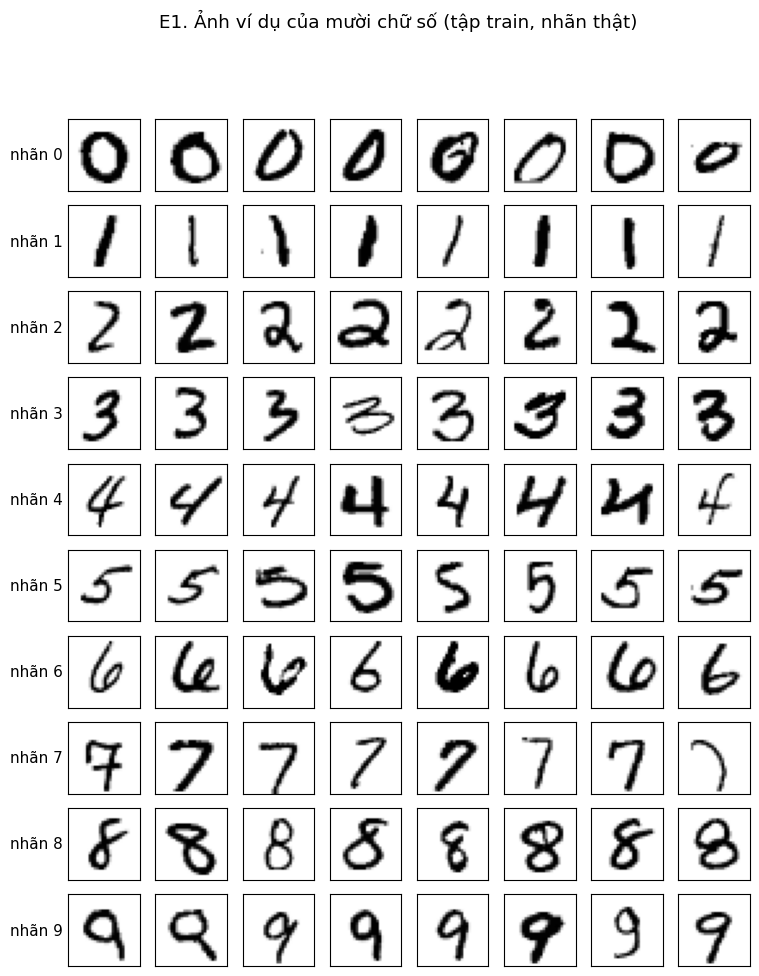

In [25]:
n_per_class = 8
fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.1, 10 * 1.1))

for digit in range(10):
  idx = np.where(y_train == digit)[0][:n_per_class]
  for col, i in enumerate(idx):
    axes[digit, col].imshow(X_train[i].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    axes[digit, col].set_xticks([])
    axes[digit, col].set_yticks([])
  axes[digit, 0].set_ylabel(f"nhãn {digit}", rotation=0, ha="right", va="center")

fig.suptitle("E1. Ảnh ví dụ của mười chữ số (tập train, nhãn thật)")
save_figure(fig, "eda_sample_grid")

### 3.1.1 Nhận xét ảnh ví dụ (E1)

* Lưới ảnh minh họa cho thấy các mẫu cùng nhãn có thể khác nhau về độ nghiêng, độ dày nét và hình dạng (ví dụ chữ số 0 có mẫu tròn to, mẫu thuôn dài; chữ số 7 có mẫu có gạch ngang hoặc không).
* Một số kiểu viết của các chữ số 4, 7 hoặc 9 có nét gần nhau, có khả năng xuất hiện nhầm lẫn khi phân lớp.


## 3.2 E2. Phân bố lớp trên train, validation và test

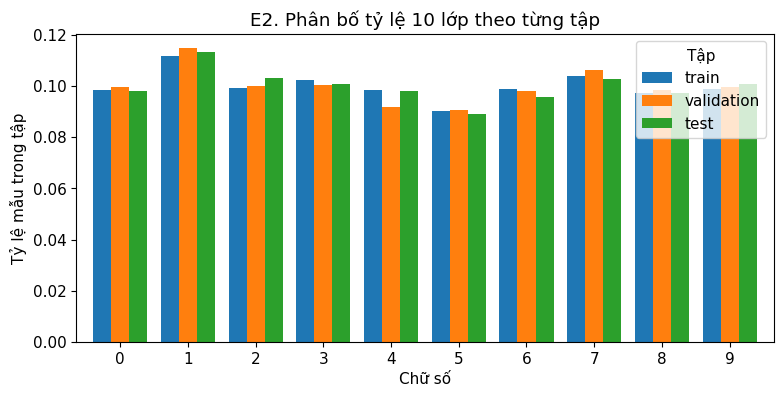

,train_count,validation_count,test_count,train_ratio,validation_ratio,test_ratio
digit,,,,,,
0,4927,996,980,0.0985,0.0996,0.0980
1,5594,1148,1135,0.1119,0.1148,0.1135
2,4959,999,1032,0.0992,0.0999,0.1032
3,5126,1005,1010,0.1025,0.1005,0.1010
4,4923,919,982,0.0985,0.0919,0.0982
5,4516,905,892,0.0903,0.0905,0.0892
6,4938,980,958,0.0988,0.0980,0.0958
7,5201,1064,1028,0.1040,0.1064,0.1028
8,4865,986,974,0.0973,0.0986,0.0974


In [26]:
class_count = pd.DataFrame({name: np.bincount(y, minlength=10) for name, (_, y) in SPLITS.items()})
class_count.index.name = "digit"
class_ratio = class_count / class_count.sum()

fig, ax = plt.subplots(figsize=(9, 4))
class_ratio.plot(kind="bar", ax=ax, width=0.8)
ax.set_xlabel("Chữ số")
ax.set_ylabel("Tỷ lệ mẫu trong tập")
ax.set_title("E2. Phân bố tỷ lệ 10 lớp theo từng tập")
ax.legend(title="Tập")
ax.tick_params(axis="x", rotation=0)
save_figure(fig, "eda_class_distribution")

save_table(class_count.add_suffix("_count").join(class_ratio.add_suffix("_ratio")), "eda_class_distribution", index=True)

### 3.2.1 Nhận xét phân bố lớp (E2)

Phân bố lớp giữa train, validation và test tương đối gần nhau. Chữ số 1 có tỷ lệ cao nhất (khoảng 11,2–11,5%), trong khi chữ số 5 thấp nhất (khoảng 9%). Điều này cho thấy mức mất cân bằng lớp không lớn; tuy nhiên, độ chính xác tổng thể vẫn cần được xem cùng Precision, Recall và F1 macro.


## 3.3 E3. Cường độ pixel và độ lệch chuẩn theo vị trí

In [27]:
pixel_std = X_train.std(axis=0)
nonzero_values = X_train[X_train > 0]

df_pixel = pd.DataFrame({
    "metric": ["Tỷ lệ pixel bằng 0", "Tỷ lệ pixel bằng 1", "Số pixel khác 0 trung bình mỗi ảnh",
               "Số vị trí pixel luôn bằng 0 trên train", "Số vị trí pixel có phương sai bằng 0"],
    "value": pd.Series([float((X_train == 0).mean()), float((X_train == 1).mean()),
                        float((X_train > 0).sum(axis=1).mean()),
                        int((X_train.max(axis=0) == 0).sum()), int((pixel_std == 0).sum())], dtype=object),
})
save_table(df_pixel, "eda_pixel_statistics")

,metric,value
0,Tỷ lệ pixel bằng 0,0.8088
1,Tỷ lệ pixel bằng 1,0.0066
2,Số pixel khác 0 trung bình mỗi ảnh,149.9026
3,Số vị trí pixel luôn bằng 0 trên train,71
4,Số vị trí pixel có phương sai bằng 0,71


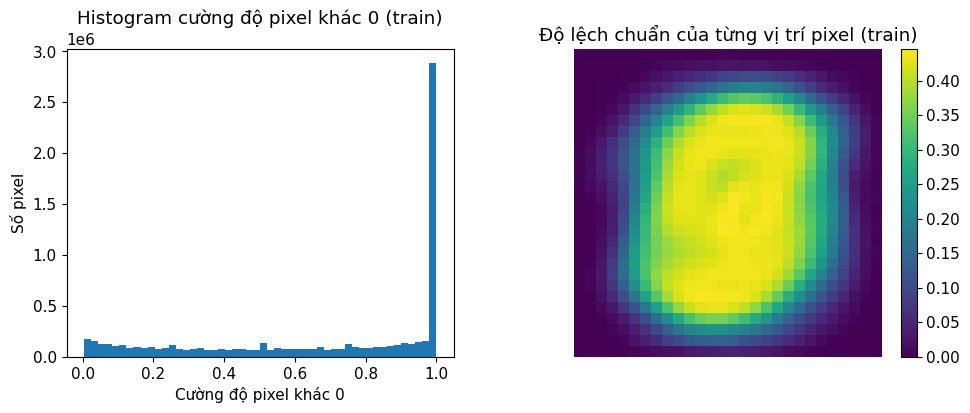

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(nonzero_values, bins=50)
axes[0].set_xlabel("Cường độ pixel khác 0")
axes[0].set_ylabel("Số pixel")
axes[0].set_title("Histogram cường độ pixel khác 0 (train)")
im = axes[1].imshow(pixel_std.reshape(28, 28), cmap="viridis")
axes[1].set_title("Độ lệch chuẩn của từng vị trí pixel (train)")
axes[1].axis("off")

fig.colorbar(im, ax=axes[1], fraction=0.046)
save_figure(fig, "eda_pixel_statistics")

### 3.3.1 Nhận xét cường độ pixel và độ lệch chuẩn (E3)

Trong tập train, khoảng **80,88%** giá trị pixel bằng 0; trung bình mỗi ảnh có khoảng **149,9** pixel **khác 0**. Có **71** vị trí pixel luôn bằng 0 trên tập train, tương ứng với phương sai bằng 0. Bản đồ độ lệch chuẩn cho thấy biến thiên chủ yếu tập trung ở vùng chứa nét chữ, trong khi các vị trí gần rìa ảnh có ít biến thiên.


## 3.4 E4. Ảnh trung bình theo lớp và tổng cường độ pixel

Tổng cường độ pixel của một ảnh là tổng 784 giá trị pixel trong `[0, 1]`; số pixel khác 0 được báo cáo thêm làm số đo thứ hai.

In [29]:
class_means = np.stack([X_train[y_train == d].mean(axis=0) for d in range(10)])
intensity_sum = X_train.sum(axis=1)
nonzero_count = (X_train > 0).sum(axis=1)
df_ink = pd.DataFrame({
    "digit": range(10),
    "mean_intensity_sum": [intensity_sum[y_train == d].mean() for d in range(10)],
    "mean_nonzero_pixels": [nonzero_count[y_train == d].mean() for d in range(10)],
})
save_table(df_ink, "eda_class_intensity")

,digit,mean_intensity_sum,mean_nonzero_pixels
0,0,135.7805,191.8384
1,1,59.5724,85.8638
2,2,117.0873,169.1583
3,3,110.8181,163.2275
4,4,95.0166,141.6852
5,5,101.1579,152.6258
6,6,107.5900,156.8957
7,7,89.5716,131.1311
8,8,117.6089,173.2781
9,9,95.9909,142.9051


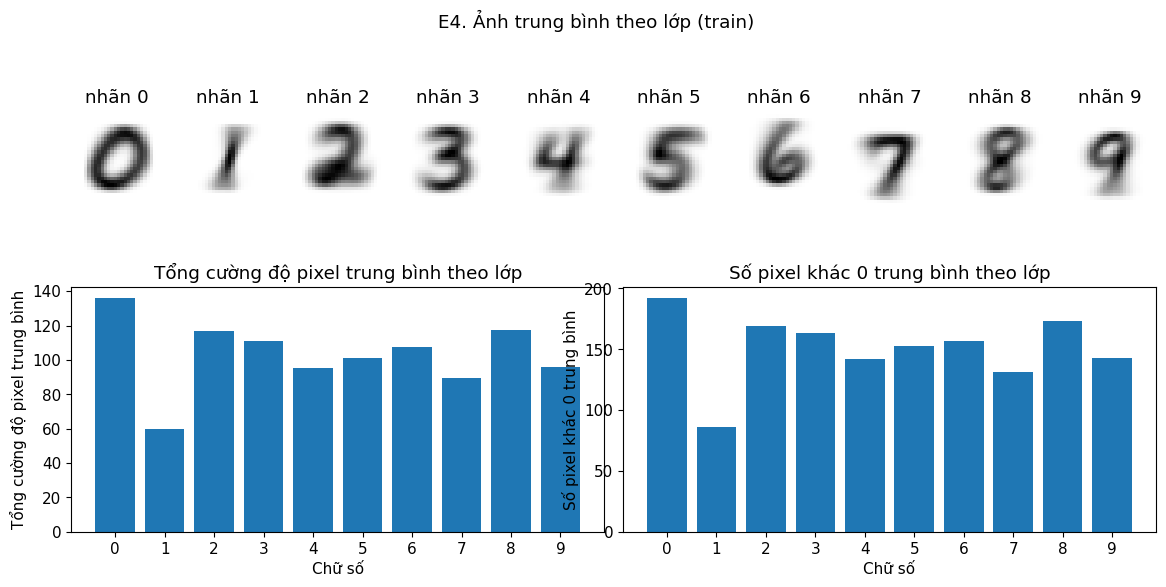

In [30]:
fig = plt.figure(figsize=(14, 6))
grid = fig.add_gridspec(2, 10, height_ratios=[1, 1.4])
for d in range(10):
  ax = fig.add_subplot(grid[0, d])
  ax.imshow(class_means[d].reshape(28, 28), cmap="gray_r")
  ax.set_title(f"nhãn {d}")
  ax.axis("off")

ax_sum = fig.add_subplot(grid[1, :5])
ax_sum.bar(df_ink["digit"], df_ink["mean_intensity_sum"])
ax_sum.set_xticks(range(10))
ax_sum.set_xlabel("Chữ số")
ax_sum.set_ylabel("Tổng cường độ pixel trung bình")
ax_sum.set_title("Tổng cường độ pixel trung bình theo lớp")

ax_cnt = fig.add_subplot(grid[1, 5:])
ax_cnt.bar(df_ink["digit"], df_ink["mean_nonzero_pixels"])
ax_cnt.set_xticks(range(10))
ax_cnt.set_xlabel("Chữ số")
ax_cnt.set_ylabel("Số pixel khác 0 trung bình")
ax_cnt.set_title("Số pixel khác 0 trung bình theo lớp")

fig.suptitle("E4. Ảnh trung bình theo lớp (train)")
save_figure(fig, "eda_class_means")

### 3.4.1 Nhận xét ảnh trung bình theo lớp (E4)

* Ảnh trung bình làm nổi bật những vùng thường có nét chữ trong mỗi lớp, đồng thời làm mờ các khác biệt giữa các mẫu.
* Trong tập train, chữ số 0 có tổng cường độ pixel trung bình cao nhất (khoảng **135,78**), còn chữ số 1 có tổng thấp nhất (khoảng **59,57**). Đây là thống kê mô tả hình dạng nét chữ , không phải chỉ số trực tiếp về độ khó phân lớp: chữ số 1 chỉ là 1 đường thẳng dọc, còn số 0 thì là 1 đường elip tương đối kín.


## 3.5 E5. Khoảng cách Euclid giữa các ảnh trung bình

In [31]:
diff = class_means[:, None, :] - class_means[None, :, :]
centroid_dist = np.sqrt((diff ** 2).sum(axis=2))
df_centroid = pd.DataFrame(centroid_dist, index=range(10), columns=range(10))
df_centroid.index.name = "digit"
save_table(df_centroid, "eda_centroid_distance", index=True)

pairs = [(a, b, centroid_dist[a, b]) for a in range(10) for b in range(a + 1, 10)]
df_closest = pd.DataFrame(sorted(pairs, key=lambda p: p[2])[:3],
                          columns=["digit_a", "digit_b", "euclid_distance"])
eda_pair_set = {(int(a), int(b)) for a, b in zip(df_closest["digit_a"], df_closest["digit_b"])}
save_table(df_closest, "eda_closest_pairs")

,digit_a,digit_b,euclid_distance
0,4,9,2.4840
1,7,9,2.9902
2,5,8,3.0987


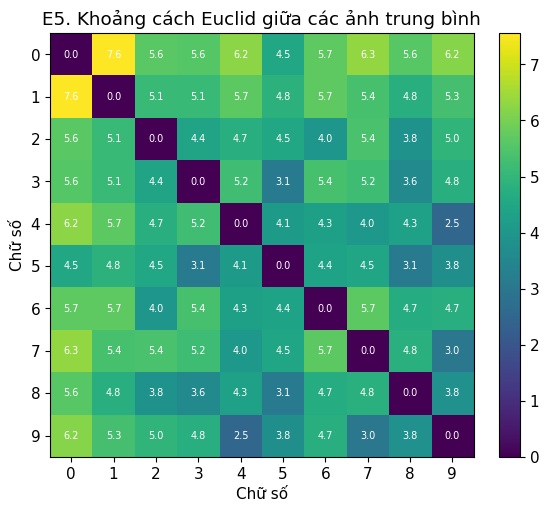

In [32]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(centroid_dist, cmap="viridis")
for i in range(10):
  for j in range(10):
    ax.text(j, i, f"{centroid_dist[i, j]:.1f}", ha="center", va="center", fontsize=7, color="white")

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Chữ số")
ax.set_ylabel("Chữ số")
ax.set_title("E5. Khoảng cách Euclid giữa các ảnh trung bình")

fig.colorbar(im, ax=ax, fraction=0.046)
save_figure(fig, "eda_centroid_distance")

### 3.5.1 Nhận xét khoảng cách giữa các ảnh trung bình (E5)

* Ba cặp ảnh trung bình có khoảng cách Euclid nhỏ nhất là **(4, 9): 2,4840**, **(7, 9): 2,9902** và **(5, 8): 3,0987**.
* Khoảng cách nhỏ phản ánh mức gần nhau của **ảnh trung bình**, không đồng nghĩa hai lớp có cùng phân phối hoặc chắc chắn bị nhầm lẫn nhiều nhất.


# 4. Kiểm thử các thành phần thuật toán

Bộ kiểm thử `tests/test_models.py` trong thư mục mã nguồn (`PROJECT_ROOT`) được chạy bằng `pytest`. Các trường hợp kiểm thử bao gồm tính toán xác suất của Naive Bayes, gradient và ổn định số học của Softmax, gradient của MLP so với autograd, SGD kết hợp Momentum, Dropout, Early Stopping, biểu quyết đa số của Random Forest và các thuộc tính/trường hợp biên của MLP. Kết quả chi tiết được xuất ra các tệp dưới thư mục đầu ra `OUTPUT_ROOT` tại đường dẫn `results/unit_tests.csv` và `results/pytest_report.xml`.

In [33]:
# Đọc kết quả pytest bằng JUnit XML, không parse output màu của Terminal.
import xml.etree.ElementTree as ET

TEST_FILE = PROJECT_ROOT / "tests" / "test_models.py"
PYTEST_XML = RESULT_DIR / "pytest_report.xml"
env = {**os.environ, "PYTHONPATH": str(PROJECT_ROOT), "NO_COLOR": "1"}
result = subprocess.run(
    [sys.executable, "-m", "pytest", "-v", "--color=no", "-p", "no:cacheprovider",
     f"--junitxml={PYTEST_XML}", str(TEST_FILE)],
    cwd=PROJECT_ROOT, env=env, capture_output=True, text=True,
    encoding="utf-8", errors="replace",
)
print(result.stdout)
if result.stderr:
  print(result.stderr)

if not PYTEST_XML.exists():
  raise RuntimeError("Pytest không tạo được báo cáo XML. Kiểm tra output ở trên.")

root = ET.parse(PYTEST_XML).getroot()
test_rows = []
for case in root.iter("testcase"):
  if case.find("failure") is not None:
    status = "FAILED"
  elif case.find("error") is not None:
    status = "ERROR"
  elif case.find("skipped") is not None:
    status = "SKIPPED"
  else:
    status = "PASSED"
  test_rows.append({"test": case.get("name"), "status": status})

df_tests = pd.DataFrame(test_rows, columns=["test", "status"])
print("Số test PASSED:", int((df_tests["status"] == "PASSED").sum()),
      "| tổng số test:", len(df_tests))
save_table(df_tests, "unit_tests")
if result.returncode != 0 or len(df_tests) != 12 or not df_tests["status"].eq("PASSED").all():
  raise RuntimeError("Unit test chưa đạt 12/12 PASSED. Xem output và results/unit_tests.csv.")

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
rootdir: /content/mnist_v1_3_source_8af82b05e98f
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... collected 12 items

tests/test_models.py::test_naive_bayes PASSED                            [  8%]
tests/test_models.py::test_softmax_gradient PASSED                       [ 16%]
tests/test_models.py::test_softmax_stability PASSED                      [ 25%]
tests/test_models.py::test_mlp_gradient PASSED                           [ 33%]
tests/test_models.py::test_sgd_momentum PASSED                           [ 41%]
tests/test_models.py::test_dropout PASSED                                [ 50%]
tests/test_models.py::test_early_stopping PASSED                         [ 58%]
tests/test_models.py::test_forest_voting PASSED                          [ 66%]
tests/test_models.py::test_mlp_clas

## 4.1 Kết quả kiểm thử

Cả **12/12 kiểm thử** trong `tests/test_models.py` đều có trạng thái `PASSED` ở lần chạy được ghi nhận. Kết quả này cung cấp bằng chứng rằng các thành phần được kiểm tra hoạt động phù hợp với kỳ vọng trên những trường hợp thử nghiệm đã thiết kế. Tuy nhiên, unit test không chứng minh mọi trường hợp đầu vào hoặc toàn bộ thuật toán đều đúng tuyệt đối.


# 5. Minh họa phương pháp

Các sơ đồ P1–P3 được vẽ bằng Matplotlib; P4 là bản đồ nhiệt trọng số của Softmax Regression tại mục 7.6. Các sơ đồ kiến trúc ở mục này mang tính minh họa và nên được đọc cùng cấu hình cụ thể của từng thí nghiệm.


In [34]:
def draw_flow(ax, labels, y=0.5, width=0.15, height=0.3):
  xs = np.linspace(width / 2 + 0.01, 1 - width / 2 - 0.01, len(labels))
  for x, text in zip(xs, labels):
    ax.add_patch(FancyBboxPatch((x - width / 2, y - height / 2), width, height,
                                boxstyle="round,pad=0.01", fill=False))
    ax.text(x, y, text, ha="center", va="center", fontsize=9)
  for left, right in zip(xs[:-1], xs[1:]):
    ax.annotate("", xy=(right - width / 2, y), xytext=(left + width / 2, y),
                arrowprops=dict(arrowstyle="->"))
  ax.set_xlim(0, 1)
  ax.set_ylim(0, 1)
  ax.axis("off")
  return xs

## 5.1 P1. Quy trình thực nghiệm

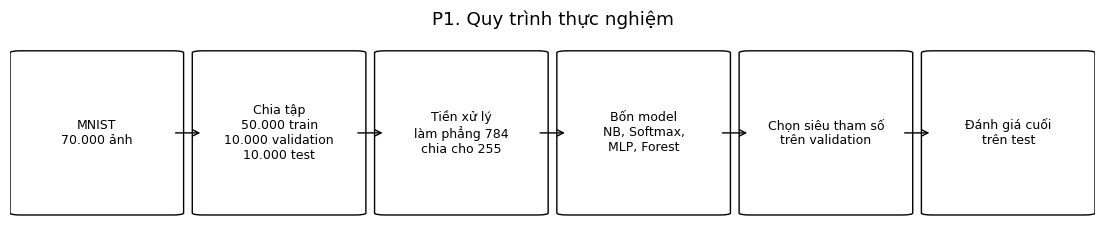

In [35]:
fig, ax = plt.subplots(figsize=(14, 2.6))
draw_flow(ax, ["MNIST\n70.000 ảnh", "Chia tập\n50.000 train\n10.000 validation\n10.000 test",
               "Tiền xử lý\nlàm phẳng 784\nchia cho 255", "Bốn model\nNB, Softmax,\nMLP, Forest",
               "Chọn siêu tham số\ntrên validation", "Đánh giá cuối\ntrên test"], width=0.14, height=0.8)
ax.set_title("P1. Quy trình thực nghiệm")
save_figure(fig, "diagram_pipeline")

## 5.2 P2. Kiến trúc MLP baseline

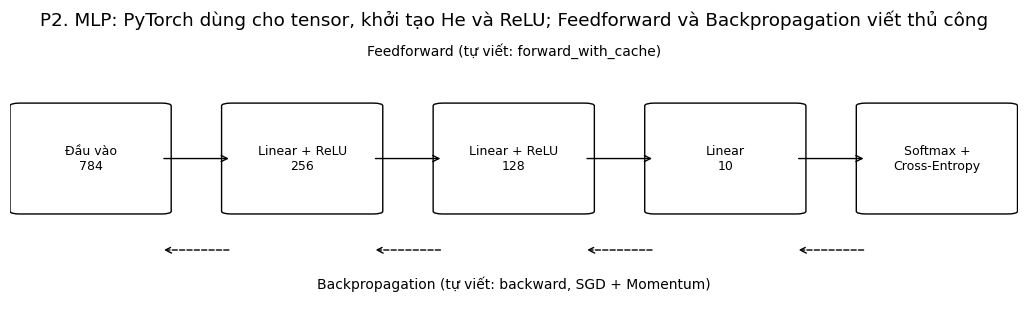

In [36]:
fig, ax = plt.subplots(figsize=(13, 3.6))
xs = draw_flow(ax, ["Đầu vào\n784", "Linear + ReLU\n256", "Linear + ReLU\n128", "Linear\n10", "Softmax +\nCross-Entropy"],
               y=0.55, width=0.14, height=0.38)
ax.text(0.5, 0.92, "Feedforward (tự viết: forward_with_cache)", ha="center", fontsize=10)

for left, right in zip(xs[:-1], xs[1:]):
  ax.annotate("", xy=(left + 0.07, 0.22), xytext=(right - 0.07, 0.22),
              arrowprops=dict(arrowstyle="->", linestyle="--"))

ax.text(0.5, 0.08, "Backpropagation (tự viết: backward, SGD + Momentum)", ha="center", fontsize=10)
ax.set_title("P2. MLP: PyTorch dùng cho tensor, khởi tạo He và ReLU; Feedforward và Backpropagation viết thủ công")
save_figure(fig, "diagram_mlp")

**Ghi chú**: Sơ đồ là kiến trúc baseline 784–256–128–10 (M0). Mô hình cuối sau khi khảo sát siêu tham số là 784–1024–10 (mục 8.9).

## 5.3 P3. Random Forest

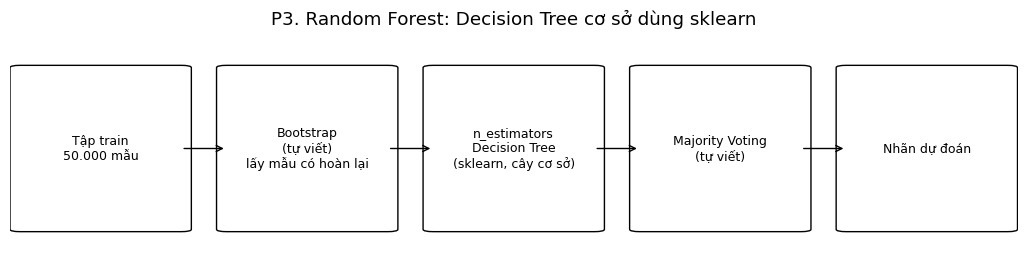

In [37]:
fig, ax = plt.subplots(figsize=(13, 3))
draw_flow(ax, ["Tập train\n50.000 mẫu", "Bootstrap\n(tự viết)\nlấy mẫu có hoàn lại", "n_estimators\nDecision Tree\n(sklearn, cây cơ sở)",
               "Majority Voting\n(tự viết)", "Nhãn dự đoán"], y=0.5, width=0.16, height=0.7)
ax.set_title("P3. Random Forest: Decision Tree cơ sở dùng sklearn")
save_figure(fig, "diagram_random_forest")

## 5.4 Diễn giải các sơ đồ

- **P1:** Minh họa chuỗi xử lý từ dữ liệu đầu vào, huấn luyện, lựa chọn siêu tham số đến đánh giá cuối; các tập train, validation và test có vai trò riêng.
- **P2:** Minh họa một kiến trúc MLP gồm hai lớp ẩn (256 và 128 neuron), cùng quá trình lan truyền xuôi và lan truyền ngược. Đây là **kiến trúc baseline ở mục 8.1**, không phải kiến trúc cuối được chọn ở mục 8.9.
- **P3:** Minh họa cách Random Forest kết hợp các cây huấn luyện trên những mẫu bootstrap và đưa ra dự đoán bằng biểu quyết đa số. Việc xây dựng cây cơ sở sử dụng `DecisionTreeClassifier` của scikit-learn.


# 6. Naive Bayes: cấu hình cơ sở và thí nghiệm

## 6.1 Baseline `NaiveBayes(alpha=0.01)`

Huấn luyện trên train, đánh giá trên train và validation. Chưa dùng test.

In [38]:
nb_baseline = NaiveBayes(alpha=0.01)
row_nb = summarize_experiment(nb_baseline, {"model": "Naive Bayes", "alpha": 0.01})
save_table(pd.DataFrame([row_nb]), "nb_baseline")

[CACHE SAVED] NaiveBayes / experiment (0.1s)


,model,alpha,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s
0,Naive Bayes,0.0100,0.8243,0.8257,0.8231,0.8237,-0.0014,0.0656,0.0257


### 6.1.1 Kết quả cấu hình cơ sở

* Multinomial Naive Bayes với $\alpha=0{,}01$ đạt Accuracy **82,43%** trên train và **82,57%** trên validation. Chênh lệch nhỏ giữa hai tập không cho thấy dấu hiệu overfitting đáng kể ở cấu hình này.
* Độ chính xác còn hạn chế có thể liên quan đến giả định độc lập có điều kiện giữa các pixel.


## 6.2 Prior, tổng đếm pixel theo lớp và đối chiếu với `sklearn.naive_bayes.MultinomialNB`

Cùng `alpha` và cùng `X_train`. Model sklearn chỉ dùng để đối chiếu, không thay thế model tự cài đặt.

In [39]:
sk_nb = MultinomialNB(alpha=nb_baseline.alpha).fit(X_train, y_train)
nb_classes = nb_baseline.classes_

own_log_prior = np.log([nb_baseline.priors_[c] for c in nb_classes])
own_log_theta = np.stack([
    np.log((nb_baseline.means_[c] + nb_baseline.alpha) / (nb_baseline.means_[c] + nb_baseline.alpha).sum())
    for c in nb_classes
])

df_nb_prior = pd.DataFrame({
    "digit": nb_classes,
    "train_count": np.bincount(y_train, minlength=10),
    "prior_own": [nb_baseline.priors_[c] for c in nb_classes],
    "prior_sklearn": np.exp(sk_nb.class_log_prior_),
    "pixel_count_sum_own": [nb_baseline.means_[c].sum() for c in nb_classes],
    "pixel_count_sum_sklearn": sk_nb.feature_count_.sum(axis=1),
})
save_table(df_nb_prior, "nb_prior_pixel_counts")

,digit,train_count,prior_own,prior_sklearn,pixel_count_sum_own,pixel_count_sum_sklearn
0,0,4927,0.0985,0.0985,668994.3750,668990.3268
1,1,5594,0.1119,0.1119,333250.3125,333248.1087
2,2,4959,0.0992,0.0992,580638.8125,580636.1382
3,3,5126,0.1025,0.1025,568056.6875,568053.6873
4,4,4923,0.0985,0.0985,467768.4375,467766.5767
5,5,4516,0.0903,0.0903,456830.1875,456828.9651
6,6,4938,0.0988,0.0988,531282.0625,531279.4437
7,7,5201,0.1040,0.1040,465864.3750,465862.0040
8,8,4865,0.0973,0.0973,572170.1250,572167.3227
9,9,4951,0.0990,0.0990,475252.9375,475250.8945


In [40]:
df_nb_check = pd.DataFrame([{
    "max_abs_diff_log_prior": np.abs(own_log_prior - sk_nb.class_log_prior_).max(),
    "max_abs_diff_log_likelihood": np.abs(own_log_theta - sk_nb.feature_log_prob_).max(),
    "val_prediction_agreement": float((sk_nb.predict(X_val) == nb_baseline.predict(X_val)).mean()),
}])
save_table(df_nb_check, "nb_sklearn_check")

,max_abs_diff_log_prior,max_abs_diff_log_likelihood,val_prediction_agreement
0,0.0000,0.0000,1.0000


### 6.2.1 Đối chiếu Naive Bayes với scikit-learn

Sai khác lớn nhất giữa log prior và log likelihood của hai cách cài đặt được hiển thị là **0,0000** ở độ chính xác bốn chữ số thập phân; dự đoán trên validation trùng nhau **100%**. Kết quả cho thấy hai cách cài đặt phù hợp với nhau trong phép đối chiếu này, nhưng không có nghĩa mọi phép tính nội bộ đều giống nhau tuyệt đối.


## 6.3 N1. Ảnh hưởng của Laplace smoothing `alpha`

Chọn `alpha` tốt nhất theo validation accuracy.

In [41]:
NB_ALPHAS = [0.001, 0.01, 0.1, 1, 10]
df_nb_alpha = pd.DataFrame([
    summarize_experiment(NaiveBayes(alpha=alpha), {"alpha": alpha}) for alpha in NB_ALPHAS
])
best_alpha = float(df_nb_alpha.loc[df_nb_alpha["val_acc"].idxmax(), "alpha"])
print("alpha tốt nhất theo validation accuracy:", best_alpha)
save_table(df_nb_alpha, "nb_alpha_sweep")

[CACHE SAVED] NaiveBayes / experiment (0.1s)
[CACHE HIT] NaiveBayes / experiment
[CACHE SAVED] NaiveBayes / experiment (0.1s)
[CACHE SAVED] NaiveBayes / experiment (0.1s)
[CACHE SAVED] NaiveBayes / experiment (0.1s)
alpha tốt nhất theo validation accuracy: 0.001


,alpha,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s
0,0.0010,0.8243,0.8257,0.8231,0.8237,-0.0014,0.0737,0.0426
1,0.0100,0.8243,0.8257,0.8231,0.8237,-0.0014,0.0656,0.0651
2,0.1000,0.8240,0.8254,0.8228,0.8234,-0.0014,0.0603,0.0435
3,1.0000,0.8234,0.8249,0.8222,0.8229,-0.0015,0.0643,0.0408
4,10.0000,0.8213,0.8221,0.8200,0.8199,-0.0008,0.0637,0.0414


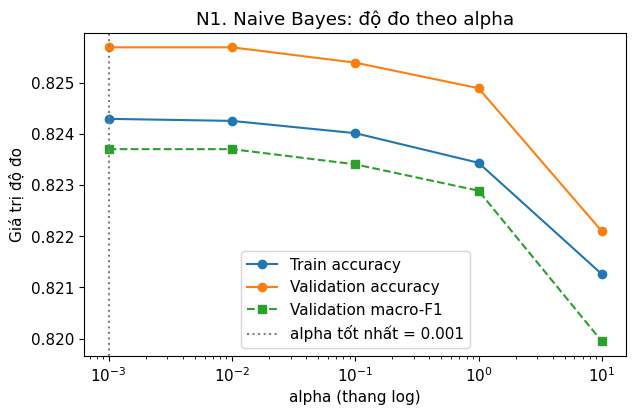

In [42]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(df_nb_alpha["alpha"], df_nb_alpha["train_acc"], marker="o", label="Train accuracy")
ax.plot(df_nb_alpha["alpha"], df_nb_alpha["val_acc"], marker="o", label="Validation accuracy")
ax.plot(df_nb_alpha["alpha"], df_nb_alpha["val_f1"], marker="s", linestyle="--", label="Validation macro-F1")
ax.axvline(best_alpha, color="gray", linestyle=":", label=f"alpha tốt nhất = {best_alpha}")

ax.set_xscale("log")
ax.set_xlabel("alpha (thang log)")
ax.set_ylabel("Giá trị độ đo")
ax.set_title("N1. Naive Bayes: độ đo theo alpha")
ax.legend()
save_figure(fig, "nb_alpha_sweep")

### 6.3.1 Ảnh hưởng của tham số làm mịn Laplace (N1)

* Accuracy validation cao nhất là 82,57%, đạt tại cả α = 0,001 và α = 0,01 (làm tròn hai chữ số phần trăm); chọn α = 0,001 theo thứ tự xét. Giá trị này nằm ở biên dưới của lưới nên chưa biết α nhỏ hơn có tốt hơn không.
* Khi α = 10, Accuracy giảm còn 82,21% (giảm 0,36 điểm). Do chưa đo độ biến thiên giữa các lần chạy, chỉ kết luận được rằng làm mịn mạnh làm giảm nhẹ Accuracy trong thí nghiệm này.


## 6.4 Heatmap `log(theta)` theo lớp

`theta` được tính từ `means_` (tổng đếm pixel theo lớp) và `alpha`: `theta = (means_ + alpha) / sum(means_ + alpha)`. Model được huấn luyện lại với `alpha` tốt nhất ở mục 6.3.

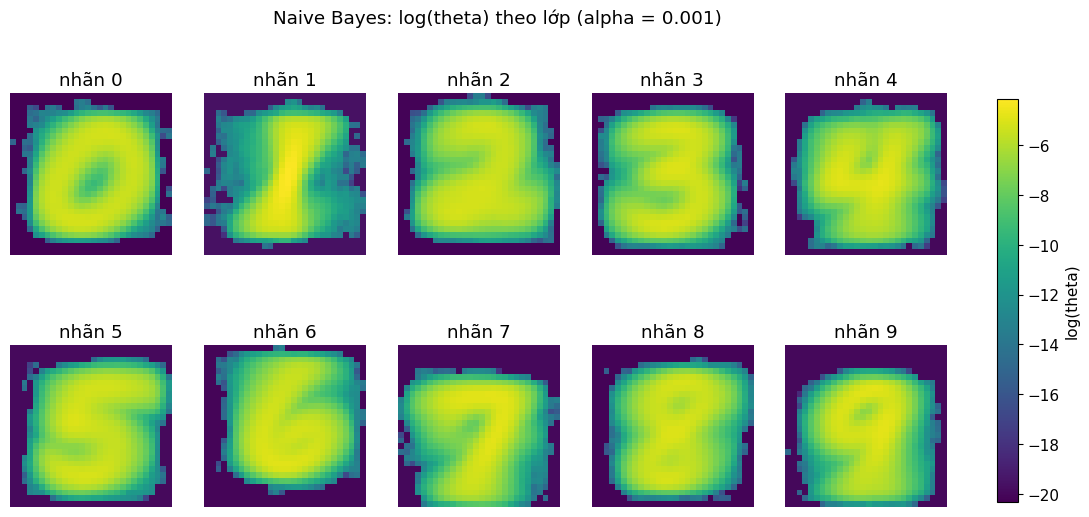

In [43]:
nb_best = NaiveBayes(alpha=best_alpha).fit(X_train, y_train)
log_theta = np.stack([
    np.log((nb_best.means_[c] + nb_best.alpha) / (nb_best.means_[c] + nb_best.alpha).sum())
    for c in nb_best.classes_
])

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for d, ax in enumerate(axes.ravel()):
  im = ax.imshow(log_theta[d].reshape(28, 28), cmap="viridis", vmin=log_theta.min(), vmax=log_theta.max())
  ax.set_title(f"nhãn {d}")
  ax.axis("off")

fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, label="log(theta)")
fig.suptitle(f"Naive Bayes: log(theta) theo lớp (alpha = {best_alpha})")
save_figure(fig, "nb_log_theta")

### 6.4.1 Bản đồ nhiệt log-xác suất của Naive Bayes

Bản đồ nhiệt $\log(\theta)$ thể hiện mức xác suất tương đối của các vị trí pixel theo từng lớp. Các vùng có giá trị lớn hơn thường trùng với vị trí xuất hiện nét chữ, còn các vùng nền có giá trị thấp hơn.


# 7. Softmax Regression: cấu hình cơ sở và thí nghiệm

## 7.1 Cấu hình cơ sở

`SoftmaxRegression(lr=0.1, max_epochs=20, batch_size=128, lam=1e-3, seed=42)` được huấn luyện trên train và đánh giá trên train/validation.


In [44]:
SM_EPOCHS = 20
SM_BATCH = 128
sm_baseline = SoftmaxRegression(lr=0.1, max_epochs=SM_EPOCHS, batch_size=SM_BATCH, lam=1e-3, seed=SEED)
row_sm = summarize_experiment(sm_baseline, {"model": "Softmax Regression", "lr": 0.1, "lam": 1e-3})
save_table(pd.DataFrame([row_sm]), "softmax_baseline")

[CACHE SAVED] SoftmaxRegression / experiment (24.4s)


,model,lr,lam,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s
0,Softmax Regression,0.1000,0.0010,0.9201,0.9154,0.9191,0.9141,0.0047,24.3882,0.0779


### 7.1.1 Kết quả cấu hình cơ sở

Với learning rate **0,1** và hệ số L2 **0,001**, Softmax Regression đạt Accuracy **91,54%** trên validation sau 20 epoch. Kết quả cao hơn cấu hình cơ sở của Naive Bayes khoảng **8,97 điểm phần trăm**. Hai mô hình sử dụng các giả định và hàm mục tiêu khác nhau, nên chênh lệch này chỉ phản ánh hiệu năng trên thiết lập thực nghiệm hiện tại.


## 7.2 S1. Đường mất mát theo epoch

`loss_history` của model là Cross-Entropy cộng số hạng L2 (`0.5 * lam * sum(W**2)`), tính trên toàn bộ tập train sau mỗi epoch.

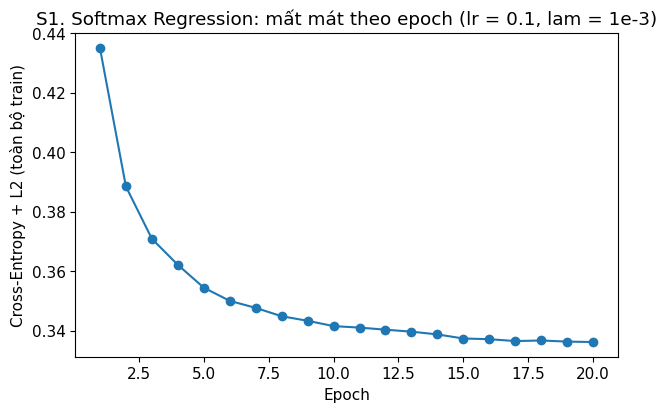

In [45]:
df_sm_loss = pd.DataFrame({"epoch": range(1, len(sm_baseline.loss_history) + 1),
                           "loss_ce_plus_l2": sm_baseline.loss_history})
save_table(df_sm_loss, "softmax_loss_history")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(df_sm_loss["epoch"], df_sm_loss["loss_ce_plus_l2"], marker="o")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy + L2 (toàn bộ train)")
ax.set_title("S1. Softmax Regression: mất mát theo epoch (lr = 0.1, lam = 1e-3)")
save_figure(fig, "softmax_loss_curve")

### 7.2.1 Đường cong mất mát (S1)

Giá trị mất mát giảm rõ trong khoảng 5 epoch đầu và thay đổi chậm hơn ở giai đoạn sau. Với cấu hình đã thử, đường cong không cho thấy biến động lớn hoặc giá trị không hữu hạn. Điều này phù hợp với quá trình tối ưu tương đối ổn định, nhưng không chứng minh mô hình đã đạt nghiệm tối ưu toàn cục.


## 7.3 S2. Ảnh hưởng của learning rate

Giữ cố định số epoch, batch size, `lam` và seed. Nếu mất mát không hữu hạn, cột `loss_finite` ghi `False`.

In [46]:
SM_LRS = [0.01, 0.05, 0.1, 0.5]
rows, sm_loss_curves = [], {}
for lr in SM_LRS:
  model = SoftmaxRegression(lr=lr, max_epochs=SM_EPOCHS, batch_size=SM_BATCH, lam=1e-3, seed=SEED)
  row = summarize_experiment(model, {"lr": lr})
  row["final_loss"] = model.loss_history[-1]
  row["loss_finite"] = bool(np.isfinite(model.loss_history).all())
  rows.append(row)
  sm_loss_curves[lr] = model.loss_history

df_sm_lr = pd.DataFrame(rows)
best_lr = float(df_sm_lr.loc[df_sm_lr["val_acc"].idxmax(), "lr"])
print("Learning rate tốt nhất theo validation accuracy:", best_lr)
save_table(df_sm_lr, "softmax_lr_sweep")

[CACHE SAVED] SoftmaxRegression / experiment (23.3s)
[CACHE SAVED] SoftmaxRegression / experiment (26.6s)
[CACHE HIT] SoftmaxRegression / experiment
[CACHE SAVED] SoftmaxRegression / experiment (22.7s)
Learning rate tốt nhất theo validation accuracy: 0.1


,lr,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s,final_loss,loss_finite
0,0.0100,0.9005,0.9009,0.8990,0.8994,-0.0004,23.3487,0.0428,0.3874,True
1,0.0500,0.9173,0.9139,0.9163,0.9127,0.0034,26.5828,0.0394,0.3412,True
2,0.1000,0.9201,0.9154,0.9191,0.9141,0.0047,24.3882,0.0413,0.3362,True
3,0.5000,0.9152,0.9103,0.9141,0.9089,0.0049,22.7284,0.0403,0.3486,True


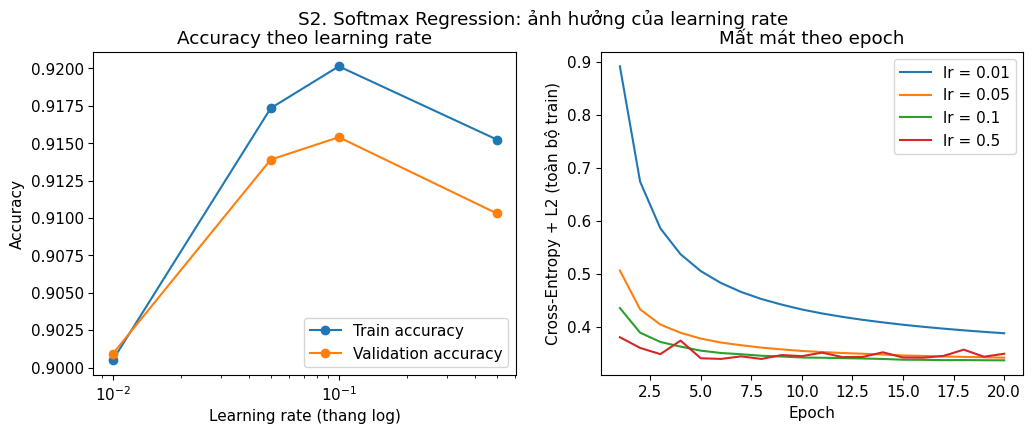

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(df_sm_lr["lr"], df_sm_lr["train_acc"], marker="o", label="Train accuracy")
axes[0].plot(df_sm_lr["lr"], df_sm_lr["val_acc"], marker="o", label="Validation accuracy")
axes[0].set_xscale("log")
axes[0].set_xlabel("Learning rate (thang log)")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy theo learning rate")
axes[0].legend()

for lr, history in sm_loss_curves.items():
  axes[1].plot(range(1, len(history) + 1), history, label=f"lr = {lr}")

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy + L2 (toàn bộ train)")
axes[1].set_title("Mất mát theo epoch")
axes[1].legend()

fig.suptitle("S2. Softmax Regression: ảnh hưởng của learning rate")
save_figure(fig, "softmax_lr_sweep")

### 7.3.1 Ảnh hưởng của learning rate (S2)

Với 20 epoch, learning rate **0,01** cho Accuracy validation **90,09%**; giá trị **0,1** đạt cao nhất trong các cấu hình thử nghiệm (**91,54%**); còn **0,5** đạt **91,03%** do vượt quá điểm tối ưu địa phương. Kết quả cho thấy lựa chọn bước học ảnh hưởng đến hiệu năng sau một số epoch cố định.


## 7.4 S3. Ảnh hưởng của hệ số L2 `lam`

Giữ learning rate được chọn ở S2 (`best_lr`); các tham số khác không đổi.

In [48]:
SM_LAMS = [0, 1e-4, 1e-3, 1e-2]
rows, sm_models = [], {}
for lam in SM_LAMS:
  model = SoftmaxRegression(lr=best_lr, max_epochs=SM_EPOCHS, batch_size=SM_BATCH, lam=lam, seed=SEED)
  rows.append(summarize_experiment(model, {"lam": lam}))
  sm_models[lam] = model

df_sm_lam = pd.DataFrame(rows)
best_row_sm = df_sm_lam.loc[df_sm_lam["val_acc"].idxmax()]
best_lam = float(best_row_sm["lam"])

print("lam tốt nhất theo validation accuracy:", best_lam)
save_table(df_sm_lam, "softmax_l2_sweep")

[CACHE SAVED] SoftmaxRegression / experiment (26.3s)
[CACHE SAVED] SoftmaxRegression / experiment (24.6s)
[CACHE HIT] SoftmaxRegression / experiment
[CACHE SAVED] SoftmaxRegression / experiment (23.7s)
lam tốt nhất theo validation accuracy: 0.0


,lam,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s
0,0.0000,0.9241,0.9187,0.9231,0.9174,0.0054,26.3253,0.0395
1,0.0001,0.9237,0.9186,0.9226,0.9174,0.0051,24.6271,0.0701
2,0.0010,0.9201,0.9154,0.9191,0.9141,0.0047,24.3882,0.0526
3,0.0100,0.8997,0.8987,0.8984,0.8972,0.0010,23.7201,0.0511


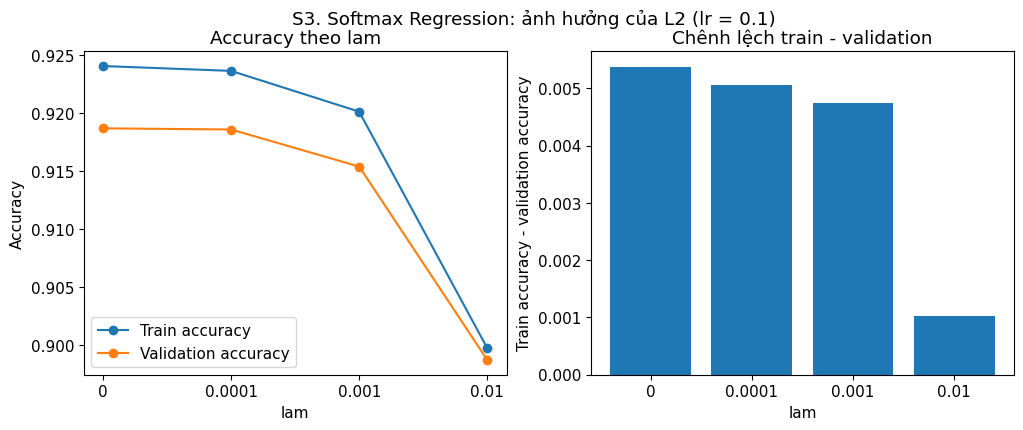

In [49]:
positions = np.arange(len(SM_LAMS))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(positions, df_sm_lam["train_acc"], marker="o", label="Train accuracy")
axes[0].plot(positions, df_sm_lam["val_acc"], marker="o", label="Validation accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy theo lam")
axes[0].legend()
axes[1].bar(positions, df_sm_lam["gap_acc"])
axes[1].set_ylabel("Train accuracy - validation accuracy")
axes[1].set_title("Chênh lệch train - validation")

for ax in axes:
  ax.set_xticks(positions)
  ax.set_xticklabels([str(lam) for lam in SM_LAMS])
  ax.set_xlabel("lam")
fig.suptitle(f"S3. Softmax Regression: ảnh hưởng của L2 (lr = {best_lr})")
save_figure(fig, "softmax_l2_sweep")

### 7.4.1 Ảnh hưởng của điều chuẩn L2 (S3)

Khi $\lambda=0$, Accuracy validation đạt **91,87%**; với $\lambda=10^{-4}$, kết quả là **91,86%**. Khi tăng lên $\lambda=0{,}01$, Accuracy giảm còn **89,87%**. Trong phạm vi siêu tham số được thử, mức điều chuẩn lớn làm giảm độ phù hợp của mô hình. Softmax Regression có **7.850 tham số nếu tính cả bias**, là số lượng tham số tương đối nhỏ, vì vậy không nên dùng số lượng trọng số $784\times10$ để mô tả toàn bộ tham số.


## 7.5 Cấu hình Softmax Regression được chọn

In [50]:
df_sm_config = pd.DataFrame([{
    "model": "Softmax Regression", "lr": best_lr, "lam": best_lam, "max_epochs": SM_EPOCHS,
    "batch_size": SM_BATCH, "seed": SEED, "val_acc": float(best_row_sm["val_acc"]),
    "val_f1": float(best_row_sm["val_f1"]),
}])
save_table(df_sm_config, "softmax_selected_config")

,model,lr,lam,max_epochs,batch_size,seed,val_acc,val_f1
0,Softmax Regression,0.1000,0.0000,20,128,42,0.9187,0.9174


### 7.5.1 Lựa chọn cấu hình Softmax Regression

Cấu hình được chọn theo Accuracy validation gồm learning rate **0,1**, $\lambda=0$, **20 epoch** và batch size **128**, đạt **91,87%** trên validation. Đây là cấu hình tốt nhất trong các giá trị đã khảo sát, không phải khẳng định tối ưu trên toàn bộ không gian siêu tham số.


## 7.6 P4. Heatmap trọng số `W[:, k]` theo từng chữ số

Dùng model Softmax với cấu hình đã chọn trên validation (huấn luyện ở mục 7.4), không dùng trọng số của sklearn.

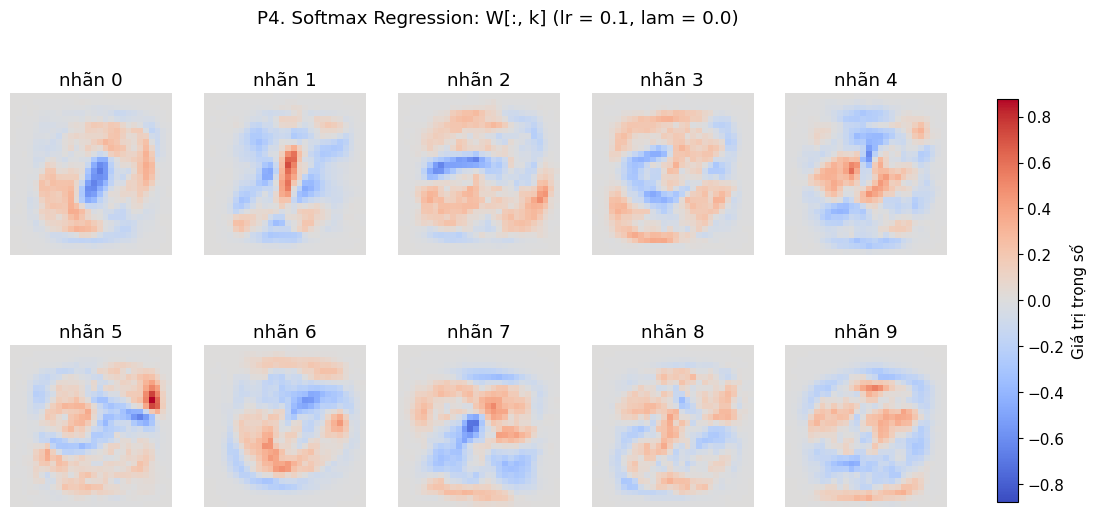

In [51]:
sm_selected = sm_models[best_lam]
w_limit = np.abs(sm_selected.W).max()

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for k, ax in enumerate(axes.ravel()):
  im = ax.imshow(sm_selected.W[:, k].reshape(28, 28), cmap="coolwarm", vmin=-w_limit, vmax=w_limit)
  ax.set_title(f"nhãn {k}")
  ax.axis("off")

fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, label="Giá trị trọng số")
fig.suptitle(f"P4. Softmax Regression: W[:, k] (lr = {best_lr}, lam = {best_lam})")
save_figure(fig, "softmax_weights")

### 7.6.1 Diễn giải bản đồ nhiệt trọng số Softmax Regression (P4)

* Bản đồ nhiệt trọng số $W[:, k]$ của mỗi chữ số thể hiện cách mô hình tuyến tính tiếp nhận dữ liệu:
  * Vùng màu đỏ (trọng số dương lớn) tương ứng với các vị trí pixel kích hoạt mạnh mẽ sự hiện diện của chữ số đó.
  * Vùng màu xanh (trọng số âm lớn) thể hiện các pixel phủ định sự tồn tại của chữ số.

Bản đồ nhiệt $W[:,k]$ cho thấy đóng góp tuyến tính của từng vị trí pixel vào điểm số của lớp $k$. Trọng số dương làm tăng điểm số của lớp khi cường độ pixel tăng, còn trọng số âm làm giảm điểm số đó. Mặc dù bản đồ nhiệt giúp chúng ta thấy rõ đóng góp tuyến tính của từng pixel đối với điểm số của lớp $k$, việc diễn giải cần xét tương quan với trọng số của các lớp khác, vì dự đoán cuối được xác định qua Softmax trên toàn bộ mười lớp.


# 8. MLP: cấu hình cơ sở và khảo sát siêu tham số

Các thí nghiệm sử dụng `MLPFromScratch` từ `mnist_colab_source.zip`. Lan truyền xuôi, lan truyền ngược và cập nhật SGD kết hợp Momentum được triển khai trong mã nguồn; quá trình huấn luyện không gọi `torch.optim` hoặc `loss.backward()`. Mỗi cấu hình khởi tạo mô hình với `seed=42`.

## 8.0 Quy ước huấn luyện và ghi nhận kết quả

- `history_` lưu `train_loss`, `train_acc`, `val_loss`, `val_acc` và `epoch_time`; `fit_time_` ghi thời gian thực hiện các bước huấn luyện, còn `eval_time_` ghi thời gian đánh giá trong `fit`.
- Khi có validation, mô hình lưu và khôi phục trọng số tại epoch có validation loss thấp nhất (`best_epoch_`), kể cả với `patience=None`; giá trị `patience` quyết định điều kiện dừng sớm.
- Các thí nghiệm cần đường cong validation (M0, M1, M5, M6 và cấu hình cuối) truyền tập validation vào `fit`. Các thí nghiệm quét siêu tham số với số epoch cố định (M2, M3, M4, M7) không truyền validation vào `fit`, sau đó đánh giá trên validation bằng hàm dự đoán.
- `train_loss` trong lịch sử có thể gồm số hạng L2, còn `val_loss` không gồm L2. Khi cần so sánh cùng định nghĩa, Notebook tính lại Cross-Entropy riêng cho train và validation.
- Thời gian `fit_time_s` được đo quanh toàn bộ lời gọi `fit()`, bao gồm các bước đánh giá phát sinh trong quá trình huấn luyện; `train_only_time_s` chỉ phản ánh thời gian huấn luyện.


In [52]:
MLP_BASE = dict(hidden_sizes=[256, 128], lr=0.05, momentum=0.9, max_epochs=10, batch_size=128,
                dropout=0.0, weight_decay=0.0, patience=None, seed=SEED, eval_batch_size=1024)
EPOCHS_SWEEP = 5
EPOCHS_DROPOUT = 20
EPOCHS_EARLY_STOP = 30
FINAL_MAX_EPOCHS = 30
FINAL_PATIENCE = 5
VAL_ARGS = (X_train, y_train, X_val, y_val)


def make_mlp(**overrides):
  return MLPFromScratch(**{**MLP_BASE, **overrides})

def n_parameters(mlp):
  return sum(p.numel() for p in mlp.model.parameters())

def mlp_cross_entropy(mlp, X, y, batch_size=1024):
  # Cross-Entropy trung bình, không có L2; model.eval() tắt Dropout khi đánh giá.
  mlp.model.eval()
  total = 0.0
  with torch.no_grad():
    for start in range(0, len(X), batch_size):
      xb = torch.from_numpy(X[start:start + batch_size]).float()
      yb = torch.from_numpy(y[start:start + batch_size]).long()
      logits, _ = forward_with_cache(mlp.model, xb)
      loss, _ = softmax_cross_entropy(logits, yb)
      total += float(loss) * len(xb)
  return total / len(X)

def history_table(history):
  df = pd.DataFrame(history)
  df.insert(0, "epoch", range(1, len(df) + 1))
  return df


def plot_history(history, best_epoch, weight_decay, title, name):
  epochs = np.arange(1, len(history["train_loss"]) + 1)
  train_label = "Train Cross-Entropy" if weight_decay == 0 else "Train Cross-Entropy + L2 (khác định nghĩa với validation)"
  fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

  axes[0].plot(epochs, history["train_loss"], marker="o", label=train_label)
  axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation Cross-Entropy")
  axes[0].set_ylabel("Loss trung bình")
  axes[0].set_title("Loss")
  axes[1].plot(epochs, history["train_acc"], marker="o", label="Train accuracy")
  axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation accuracy")
  axes[1].set_ylabel("Accuracy")
  axes[1].set_title("Accuracy")

  for ax in axes[:2]:
    ax.axvline(best_epoch, color="gray", linestyle="--", label=f"best_epoch = {best_epoch}")
    ax.legend(fontsize=8)
  axes[2].bar(epochs, history["epoch_time"])
  axes[2].set_ylabel("Giây (chỉ huấn luyện, không gồm đánh giá)")
  axes[2].set_title("Thời gian huấn luyện theo epoch")

  for ax in axes:
    ax.set_xlabel("Epoch")
  fig.suptitle(title)
  save_figure(fig, name)

## 8.1 M0. Cấu hình cơ sở

Kiến trúc `784–256–128–10` sử dụng ReLU, khởi tạo He, `lr=0.05`, `momentum=0.9`, `batch_size=128`, `max_epochs=10`, `dropout=0`, `weight_decay=0`, `patience=None`. Mốc Accuracy validation **97%** được sử dụng làm ngưỡng tham chiếu trong phép kiểm tra `val_acc_at_least_0.97`.


In [53]:
mlp_m0 = make_mlp()
row_m0 = summarize_experiment(mlp_m0, {"config": "M0", "hidden_sizes": str(MLP_BASE["hidden_sizes"])}, fit_args=VAL_ARGS)
row_m0.update(best_epoch=mlp_m0.best_epoch_, epochs_trained=mlp_m0.epochs_trained_,
              n_params=n_parameters(mlp_m0), **{"val_acc_at_least_0.97": bool(row_m0["val_acc"] >= 0.97)})
save_table(pd.DataFrame([row_m0]), "mlp_baseline")

[CACHE SAVED] MLPFromScratch / experiment (28.0s)


,config,hidden_sizes,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s,train_only_time_s,eval_time_s,diverged,best_epoch,epochs_trained,n_params,val_acc_at_least_0.97
0,M0,"[256, 128]",0.9987,0.9771,0.9987,0.9768,0.0216,28.0405,0.0813,22.1703,5.8628,False,9,10,235146,True


### 8.1.1 Kết quả MLP cơ sở (M0)

MLP với hai lớp ẩn kích thước **256** và **128** đạt Accuracy validation **97,71%**, vượt ngưỡng tham chiếu 97% trong thiết lập thực nghiệm này. Kết quả cho thấy mô hình có khả năng phân lớp tốt trên MNIST, đồng thời cần được xem xét cùng chênh lệch train–validation và các thí nghiệm điều chuẩn.


## 8.2 M1. Đường cong học (learning curves)

`weight_decay = 0` nên `train_loss` và `val_loss` trong `history_` cùng là Cross-Entropy trung bình, đo ở chế độ `eval()`. Hình gồm loss, accuracy và thời gian huấn luyện theo epoch.

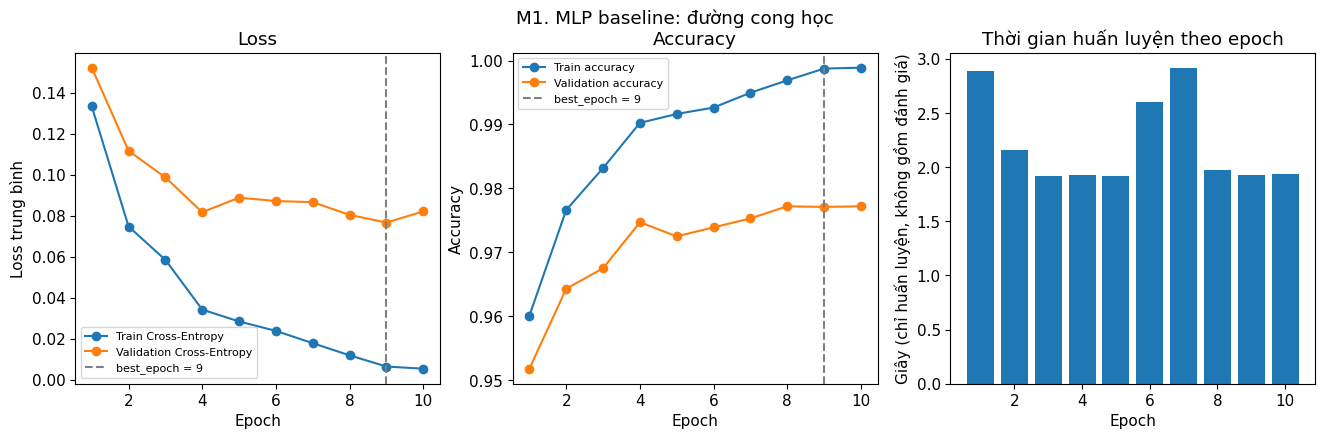

In [54]:
save_table(history_table(mlp_m0.history_), "mlp_baseline_history")
plot_history(mlp_m0.history_, mlp_m0.best_epoch_, MLP_BASE["weight_decay"],
             "M1. MLP baseline: đường cong học", "mlp_learning_curve")

### 8.2.1 Đường cong học của MLP (M1)

Loss trên train giảm mạnh theo epoch, trong khi loss validation giảm chậm hơn và có những giai đoạn tăng trở lại. Chênh lệch này gợi ý khả năng overfitting ở các epoch muộn.

## 8.3 M2. Learning rate x Momentum

15 cấu hình, mỗi cấu hình 5 epoch, `patience=None`, không truyền validation vào `fit`. `lr_eff = lr / (1 - momentum)`. Cột `diverged` lấy từ `diverged_`; cấu hình phân kỳ dừng huấn luyện sớm nên `epochs_trained` nhỏ hơn 5.

In [55]:
MLP_LRS = [0.005, 0.01, 0.05, 0.1, 0.5]
MLP_MOMENTUMS = [0, 0.5, 0.9]
rows = []
for lr in MLP_LRS:
  for momentum in MLP_MOMENTUMS:
    model = make_mlp(lr=lr, momentum=momentum, max_epochs=EPOCHS_SWEEP)
    row = summarize_experiment(model, {"lr": lr, "momentum": momentum, "lr_eff": lr / (1 - momentum)})
    row["epochs_trained"] = model.epochs_trained_
    row["final_train_loss"] = model.history_["train_loss"][-1] if model.history_["train_loss"] else np.nan
    rows.append(row)

df_mlp_lrmom = pd.DataFrame(rows)
valid_lrmom = df_mlp_lrmom.loc[
    (~df_mlp_lrmom["diverged"]) & np.isfinite(df_mlp_lrmom["val_acc"])
]
if valid_lrmom.empty:
  raise RuntimeError("Không có cấu hình MLP LR/Momentum hợp lệ: tất cả đã phân kỳ hoặc thiếu val_acc.")
best_row_lrmom = valid_lrmom.loc[valid_lrmom["val_acc"].idxmax()]

print("Cấu hình tốt nhất theo validation accuracy: lr =", best_row_lrmom["lr"], ", momentum =", best_row_lrmom["momentum"])
save_table(df_mlp_lrmom, "mlp_lr_momentum")

[CACHE SAVED] MLPFromScratch / experiment (12.4s)
[CACHE SAVED] MLPFromScratch / experiment (13.0s)
[CACHE SAVED] MLPFromScratch / experiment (13.6s)
[CACHE SAVED] MLPFromScratch / experiment (13.4s)
[CACHE SAVED] MLPFromScratch / experiment (13.8s)
[CACHE SAVED] MLPFromScratch / experiment (13.6s)
[CACHE SAVED] MLPFromScratch / experiment (13.5s)
[CACHE SAVED] MLPFromScratch / experiment (13.6s)
[CACHE SAVED] MLPFromScratch / experiment (18.7s)
[CACHE SAVED] MLPFromScratch / experiment (13.8s)
[CACHE SAVED] MLPFromScratch / experiment (13.7s)
[CACHE SAVED] MLPFromScratch / experiment (13.6s)
[CACHE SAVED] MLPFromScratch / experiment (13.4s)
[CACHE SAVED] MLPFromScratch / experiment (13.1s)
[CACHE SAVED] MLPFromScratch / experiment (17.4s)
Cấu hình tốt nhất theo validation accuracy: lr = 0.1 , momentum = 0.9


,lr,momentum,lr_eff,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s,train_only_time_s,eval_time_s,diverged,epochs_trained,final_train_loss
0,0.0050,0.0000,0.0050,0.8929,0.8913,0.8914,0.8894,0.0016,12.3738,0.1332,10.1926,2.1764,False,5,0.3945
1,0.0050,0.5000,0.0100,0.9134,0.9130,0.9124,0.9118,0.0004,13.0412,0.0838,10.5965,2.4409,False,5,0.3041
2,0.0050,0.9000,0.0500,0.9565,0.9497,0.9562,0.9492,0.0068,13.5815,0.0848,11.0822,2.4967,False,5,0.1511
3,0.0100,0.0000,0.0100,0.9137,0.9131,0.9127,0.9118,0.0006,13.3632,0.0848,10.7560,2.6050,False,5,0.3043
4,0.0100,0.5000,0.0200,0.9332,0.9287,0.9325,0.9277,0.0045,13.7692,0.0826,11.1659,2.6008,False,5,0.2351
5,0.0100,0.9000,0.1000,0.9736,0.9633,0.9734,0.9630,0.0103,13.6131,0.0840,11.0559,2.5545,False,5,0.0940
6,0.0500,0.0000,0.0500,0.9557,0.9475,0.9552,0.9468,0.0082,13.4690,0.0828,10.7988,2.6678,False,5,0.1557
7,0.0500,0.5000,0.1000,0.9724,0.9624,0.9721,0.9620,0.0100,13.5894,0.0874,11.1312,2.4558,False,5,0.0977
8,0.0500,0.9000,0.5000,0.9916,0.9725,0.9916,0.9722,0.0191,18.7076,0.1289,14.8303,3.8747,False,5,0.0284
9,0.1000,0.0000,0.1000,0.9689,0.9590,0.9685,0.9585,0.0099,13.7750,0.0838,11.2896,2.4820,False,5,0.1048


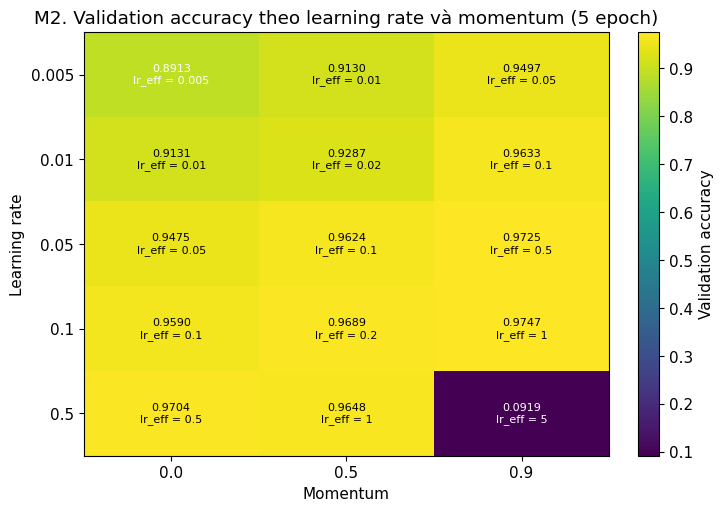

In [56]:
pivot_acc = df_mlp_lrmom.pivot(index="lr", columns="momentum", values="val_acc")
pivot_eff = df_mlp_lrmom.pivot(index="lr", columns="momentum", values="lr_eff")
fig, ax = plt.subplots(figsize=(7.5, 5.5))
im = ax.imshow(pivot_acc.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(pivot_acc.shape[1]))
ax.set_xticklabels(pivot_acc.columns)
ax.set_yticks(range(pivot_acc.shape[0]))
ax.set_yticklabels(pivot_acc.index)
mid = pivot_acc.values.mean()

for i in range(pivot_acc.shape[0]):
  for j in range(pivot_acc.shape[1]):
    ax.text(j, i, f"{pivot_acc.values[i, j]:.4f}\nlr_eff = {pivot_eff.values[i, j]:.3g}", ha="center", va="center",
            fontsize=8, color="white" if pivot_acc.values[i, j] < mid else "black")

ax.set_xlabel("Momentum")
ax.set_ylabel("Learning rate")
ax.set_title("M2. Validation accuracy theo learning rate và momentum (5 epoch)")
fig.colorbar(im, ax=ax, fraction=0.046, label="Validation accuracy")
save_figure(fig, "mlp_lr_momentum")

### 8.3.1 Tương tác learning rate và Momentum (M2)

Ở learning rate **0,005**, Accuracy validation tăng từ **89,13%** khi Momentum bằng 0 lên **94,97%** khi Momentum bằng 0,9. Với tổ hợp `lr=0.5` và `momentum=0.9`, Accuracy validation giảm xuống **9,19%**, gần mức dự đoán ngẫu nhiên của bài toán mười lớp. Tuy nhiên, cột `diverged` của lần chạy này là **False** và cả năm epoch đều hoàn thành; vì vậy chỉ có thể kết luận cấu hình hoạt động kém, **không được gọi là phân kỳ theo tiêu chí kiểm tra của mã nguồn**.


## 8.4 M3. Batch size

Mỗi cấu hình 5 epoch. Số bước cập nhật là `ceil(N_train / batch_size) * epochs_trained_`.

In [57]:
MLP_BATCHES = [16, 64, 256, 1024]
rows = []
for batch_size in MLP_BATCHES:
  model = make_mlp(batch_size=batch_size, max_epochs=EPOCHS_SWEEP)
  row = summarize_experiment(model, {"batch_size": batch_size})
  row["epochs_trained"] = model.epochs_trained_
  row["sec_per_epoch"] = (model.fit_time_ / model.epochs_trained_
                          if model.epochs_trained_ > 0 else np.nan)
  row["n_updates"] = math.ceil(len(X_train) / batch_size) * model.epochs_trained_
  rows.append(row)

df_mlp_batch = pd.DataFrame(rows)
best_row_batch = df_mlp_batch.loc[df_mlp_batch["val_acc"].idxmax()]
save_table(df_mlp_batch, "mlp_batch_size")

[CACHE SAVED] MLPFromScratch / experiment (64.0s)
[CACHE SAVED] MLPFromScratch / experiment (17.4s)
[CACHE SAVED] MLPFromScratch / experiment (11.6s)
[CACHE SAVED] MLPFromScratch / experiment (11.2s)


,batch_size,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s,train_only_time_s,eval_time_s,diverged,epochs_trained,sec_per_epoch,n_updates
0,16,0.9634,0.9517,0.9629,0.9511,0.0117,63.9720,0.0835,61.0121,2.9557,False,5,12.2024,15625
1,64,0.9902,0.9736,0.9901,0.9733,0.0166,17.4135,0.1331,14.7316,2.6795,False,5,2.9463,3910
2,256,0.9877,0.9734,0.9876,0.9731,0.0143,11.6296,0.0813,9.1669,2.4587,False,5,1.8334,980
3,1024,0.9580,0.9510,0.9576,0.9504,0.0070,11.2202,0.0814,8.6037,2.6141,False,5,1.7207,245


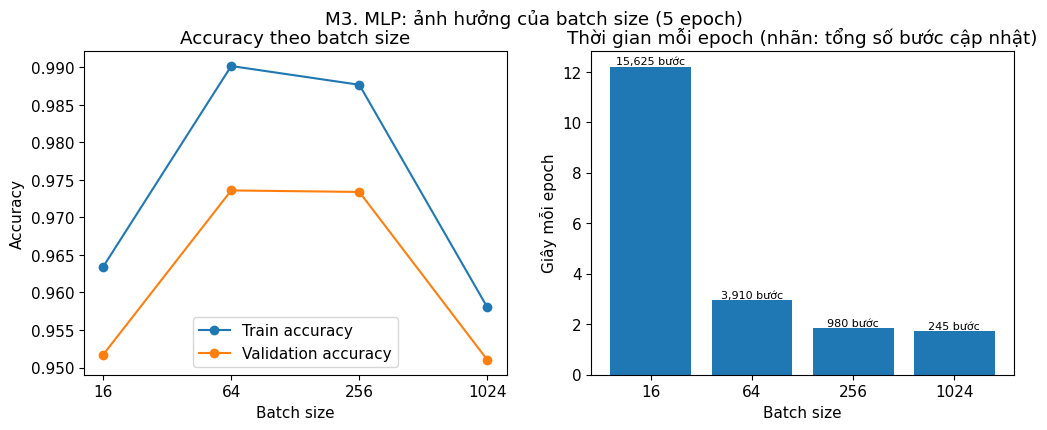

In [58]:
positions = np.arange(len(MLP_BATCHES))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(positions, df_mlp_batch["train_acc"], marker="o", label="Train accuracy")
axes[0].plot(positions, df_mlp_batch["val_acc"], marker="o", label="Validation accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy theo batch size")
axes[0].legend()

bars = axes[1].bar(positions, df_mlp_batch["sec_per_epoch"])
axes[1].bar_label(bars, labels=[f"{n:,} bước" for n in df_mlp_batch["n_updates"]], fontsize=8)
axes[1].set_ylabel("Giây mỗi epoch")
axes[1].set_title("Thời gian mỗi epoch (nhãn: tổng số bước cập nhật)")

for ax in axes:
  ax.set_xticks(positions)
  ax.set_xticklabels(MLP_BATCHES)
  ax.set_xlabel("Batch size")
fig.suptitle("M3. MLP: ảnh hưởng của batch size (5 epoch)")
save_figure(fig, "mlp_batch_size")

### 8.4.1 Ảnh hưởng của batch size (M3)

* Với batch size **16**, mô hình đạt Accuracy validation **95,17%** và thời gian huấn luyện thuần khoảng **60,57 giây** (thời gian toàn bộ `fit()` khoảng **62,56 giây**), tương ứng **15.625 bước cập nhật**.
* Batch size **1.024** đạt **95,10%**, thời gian huấn luyện thuần khoảng **6,31 giây** (toàn bộ `fit()` khoảng **8,58 giây**).
* Trong bốn giá trị khảo sát, batch size **64** đạt Accuracy validation cao nhất (**97,36%**), còn **256** đạt **97,34%** với thời gian thấp hơn. Kết quả phản ánh đánh đổi giữa số bước cập nhật, thời gian và hiệu năng trong thiết lập này.


## 8.5 M4. Kiến trúc

Năm kiến trúc, mỗi kiến trúc 5 epoch. Số tham số tính từ `model.model.parameters()`.

In [59]:
ARCHS = {"[64]": [64], "[256]": [256], "[1024]": [1024],
         "[256,128]": [256, 128], "[256,256,256,256]": [256, 256, 256, 256]}
rows = []
for arch_name, hidden in ARCHS.items():
  model = make_mlp(hidden_sizes=hidden, max_epochs=EPOCHS_SWEEP)
  row = summarize_experiment(model, {"architecture": arch_name})
  row["n_params"] = n_parameters(model)
  rows.append(row)

df_mlp_arch = pd.DataFrame(rows)
best_row_arch = df_mlp_arch.loc[df_mlp_arch["val_acc"].idxmax()]
save_table(df_mlp_arch, "mlp_architecture")

[CACHE SAVED] MLPFromScratch / experiment (4.0s)
[CACHE SAVED] MLPFromScratch / experiment (11.8s)
[CACHE SAVED] MLPFromScratch / experiment (43.7s)
[CACHE HIT] MLPFromScratch / experiment
[CACHE SAVED] MLPFromScratch / experiment (24.2s)


,architecture,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s,train_only_time_s,eval_time_s,diverged,n_params
0,[64],0.9810,0.9669,0.9808,0.9665,0.0141,3.9593,0.0375,3.2147,0.7424,False,50890
1,[256],0.9892,0.9744,0.9892,0.9742,0.0148,11.7729,0.0749,9.5747,2.1945,False,203530
2,[1024],0.9918,0.9756,0.9918,0.9754,0.0162,43.6894,0.2874,36.0381,7.6483,False,814090
3,"[256,128]",0.9916,0.9725,0.9916,0.9722,0.0191,18.7076,0.0827,14.8303,3.8747,False,235146
4,"[256,256,256,256]",0.9845,0.9676,0.9841,0.9671,0.0169,24.2286,0.1460,19.8100,4.4155,False,400906


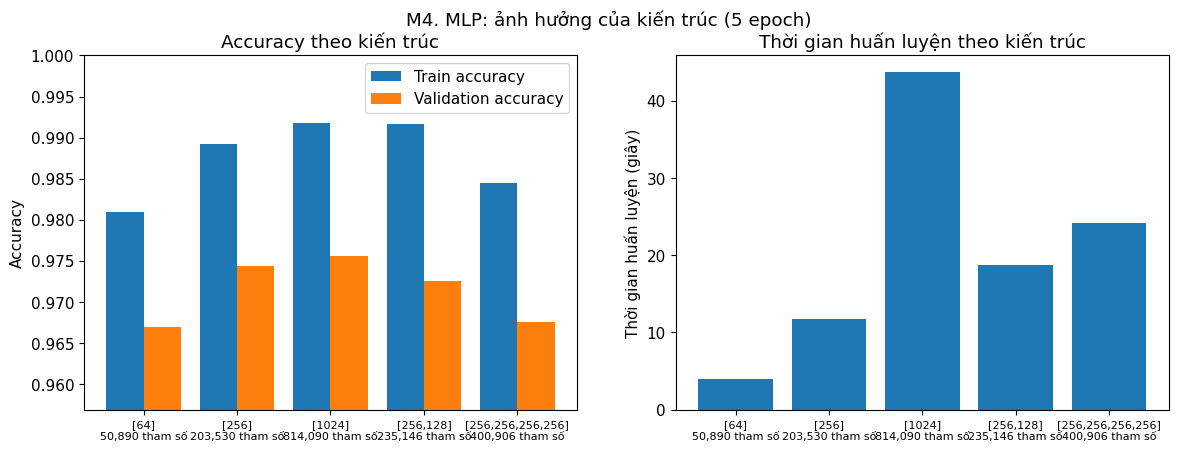

In [60]:
positions = np.arange(len(ARCHS))
tick_labels = [f"{name}\n{n:,} tham số" for name, n in zip(df_mlp_arch["architecture"], df_mlp_arch["n_params"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

axes[0].bar(positions - 0.2, df_mlp_arch["train_acc"], width=0.4, label="Train accuracy")
axes[0].bar(positions + 0.2, df_mlp_arch["val_acc"], width=0.4, label="Validation accuracy")
axes[0].set_ylim(min(df_mlp_arch["train_acc"].min(), df_mlp_arch["val_acc"].min()) - 0.01, 1.0)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy theo kiến trúc")
axes[0].legend()

axes[1].bar(positions, df_mlp_arch["fit_time_s"])
axes[1].set_ylabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Thời gian huấn luyện theo kiến trúc")

for ax in axes:
  ax.set_xticks(positions)
  ax.set_xticklabels(tick_labels, fontsize=8)
fig.suptitle("M4. MLP: ảnh hưởng của kiến trúc (5 epoch)")
save_figure(fig, "mlp_architecture")

### 8.5.1 Ảnh hưởng của kiến trúc MLP (M4)

Trong năm kiến trúc khảo sát, mạng một lớp ẩn **[1024]** đạt Accuracy validation cao nhất (**97,56%**) với **814.090 tham số** và thời gian `fit()` khoảng **38,76 giây**. Kiến trúc bốn lớp ẩn **[256, 256, 256, 256]** đạt **96,76%**. Kết quả cho thấy tăng số lớp ẩn không bảo đảm cải thiện Accuracy với cùng số epoch và cách tối ưu; chưa đủ bằng chứng để quy nguyên nhân cho hiện tượng tiêu biến gradient.


In [61]:
MLP_DROPOUTS = [0.0, 0.2, 0.5]
rows, hist_dropout = [], {}
for p in MLP_DROPOUTS:
  model = make_mlp(dropout=p, max_epochs=EPOCHS_DROPOUT)
  # fit và predict đặt model ở eval(), nên Dropout tắt khi đánh giá
  row = summarize_experiment(model, {"dropout": p}, fit_args=VAL_ARGS)
  row["best_epoch"] = model.best_epoch_
  row["epochs_trained"] = model.epochs_trained_
  rows.append(row)
  hist_dropout[p] = model.history_

df_mlp_dropout = pd.DataFrame(rows)
best_row_dropout = df_mlp_dropout.loc[df_mlp_dropout["val_acc"].idxmax()]
save_table(df_mlp_dropout, "mlp_dropout")

df_hist_dropout = pd.concat([history_table(h).assign(dropout=p) for p, h in hist_dropout.items()], ignore_index=True)
save_table(df_hist_dropout, "mlp_dropout_history")

[CACHE SAVED] MLPFromScratch / experiment (57.8s)
[CACHE SAVED] MLPFromScratch / experiment (65.9s)
[CACHE SAVED] MLPFromScratch / experiment (68.7s)


,epoch,train_loss,train_acc,val_loss,val_acc,epoch_time,dropout
0,1,0.1333,0.9601,0.1522,0.9518,1.8874,0.0000
1,2,0.0747,0.9766,0.1116,0.9643,1.9088,0.0000
2,3,0.0585,0.9832,0.0986,0.9675,2.2665,0.0000
3,4,0.0342,0.9902,0.0817,0.9747,3.0825,0.0000
4,5,0.0284,0.9916,0.0888,0.9725,1.9979,0.0000
5,6,0.0239,0.9926,0.0872,0.9739,1.9550,0.0000
6,7,0.0179,0.9950,0.0866,0.9753,1.9877,0.0000
7,8,0.0119,0.9969,0.0804,0.9772,1.9516,0.0000
8,9,0.0065,0.9987,0.0767,0.9771,3.0969,0.0000
9,10,0.0054,0.9989,0.0821,0.9772,2.3544,0.0000


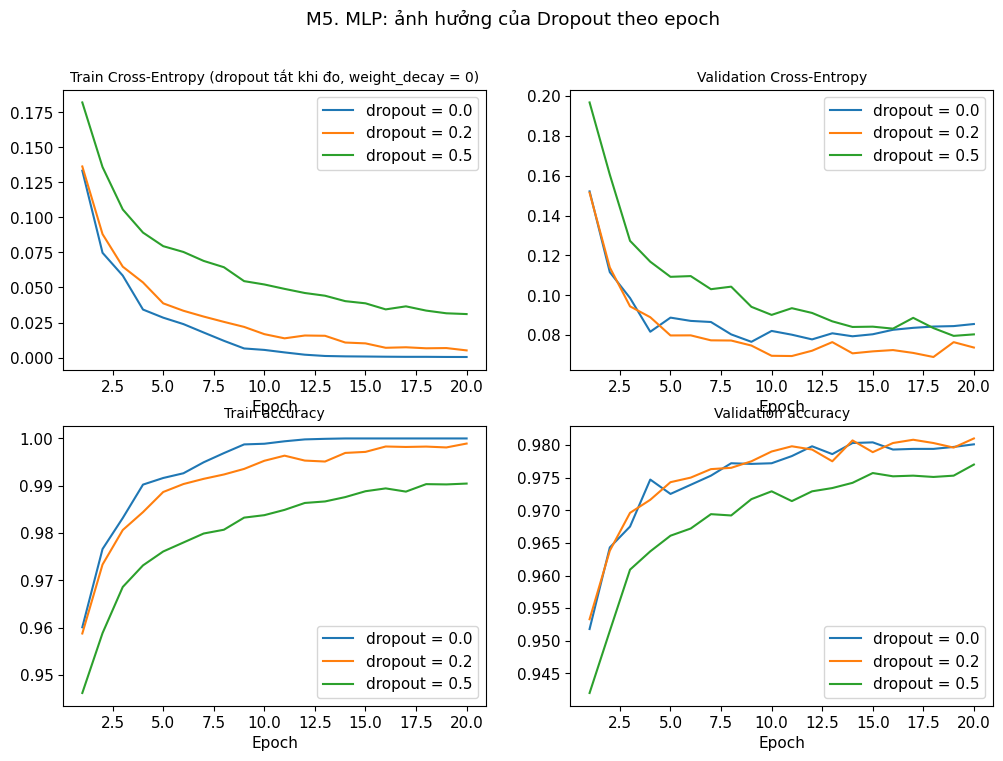

In [62]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
panels = [("train_loss", "Train Cross-Entropy (dropout tắt khi đo, weight_decay = 0)"), ("val_loss", "Validation Cross-Entropy"),
          ("train_acc", "Train accuracy"), ("val_acc", "Validation accuracy")]

for ax, (key, title) in zip(axes.ravel(), panels):
  for p, history in hist_dropout.items():
    ax.plot(np.arange(1, len(history[key]) + 1), history[key], label=f"dropout = {p}")
  ax.set_xlabel("Epoch")
  ax.set_title(title, fontsize=10)
  ax.legend()

fig.suptitle("M5. MLP: ảnh hưởng của Dropout theo epoch")
save_figure(fig, "mlp_dropout")

### 8.6.1 Ảnh hưởng của Dropout (M5)

Ở các cấu hình được thử, Accuracy validation đạt khoảng **97,71%** khi không dùng Dropout, **98,03%** với Dropout **0,2** và **97,53%** với Dropout **0,5**. Dropout 0,2 cho kết quả cao nhất trong ba giá trị khảo sát. Mức Dropout 0,5 có thể làm việc tối ưu khó hơn với cùng số epoch; kết quả chưa chứng minh mức 0,2 là tối ưu cho mọi kiến trúc do chỉ tối ưu cho seed/thí nghiệm này và chưa đánh giá qua nhiều seed khác nhau.


## 8.7 M6. Early Stopping

So sánh `patience=5` với `patience=None` trên cùng cấu hình, cùng seed, `max_epochs` bằng `EPOCHS_EARLY_STOP`. Cả hai cấu hình đều truyền validation vào `fit`, nên cả hai khôi phục trọng số ở `best_epoch_`; khác biệt là thời điểm dừng. Cấu hình thứ ba không truyền validation (không Early Stopping, không khôi phục trọng số) được thêm để so sánh với trọng số của epoch cuối.

Cột `restored_best_weights` so sánh validation loss tính lại sau `fit` với `history_["val_loss"][best_epoch_ - 1]`.

In [63]:
ES_CONFIGS = {"patience=5": 5, "patience=None": None}
rows, es_models = [], {}
for name, patience in ES_CONFIGS.items():
  model = make_mlp(max_epochs=EPOCHS_EARLY_STOP, patience=patience)
  row = summarize_experiment(model, {"config": name}, fit_args=VAL_ARGS)
  val_ce_after_fit = mlp_cross_entropy(model, X_val, y_val)
  val_ce_at_best = model.history_["val_loss"][model.best_epoch_ - 1]
  row.update(best_epoch=model.best_epoch_, epochs_trained=model.epochs_trained_,
             stopped_early=model.stopped_early_, val_ce_after_fit=val_ce_after_fit,
             val_ce_at_best_epoch=val_ce_at_best,
             restored_best_weights=bool(np.isclose(val_ce_after_fit, val_ce_at_best, rtol=1e-4)))
  rows.append(row)
  es_models[name] = model

model = make_mlp(max_epochs=EPOCHS_EARLY_STOP)
row = summarize_experiment(model, {"config": "không truyền validation"})
row.update(epochs_trained=model.epochs_trained_, stopped_early=model.stopped_early_,
           val_ce_after_fit=mlp_cross_entropy(model, X_val, y_val))
rows.append(row)

df_mlp_es = pd.DataFrame(rows)
save_table(df_mlp_es, "mlp_early_stopping")

[CACHE SAVED] MLPFromScratch / experiment (38.6s)
[CACHE SAVED] MLPFromScratch / experiment (85.9s)
[CACHE SAVED] MLPFromScratch / experiment (83.2s)


,config,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s,train_only_time_s,eval_time_s,diverged,best_epoch,epochs_trained,stopped_early,val_ce_after_fit,val_ce_at_best_epoch,restored_best_weights
0,patience=5,0.9987,0.9771,0.9987,0.9768,0.0216,38.6255,0.1380,30.2828,8.3386,False,9.0000,14,True,0.0767,0.0767,True
1,patience=None,0.9987,0.9771,0.9987,0.9768,0.0216,85.9462,0.0824,67.5922,18.3496,False,9.0000,30,False,0.0767,0.0767,True
2,không truyền validation,1.0000,0.9802,1.0000,0.9800,0.0198,83.2031,0.1402,67.6586,15.5421,False,NaN,30,False,0.0900,NaN,NaN


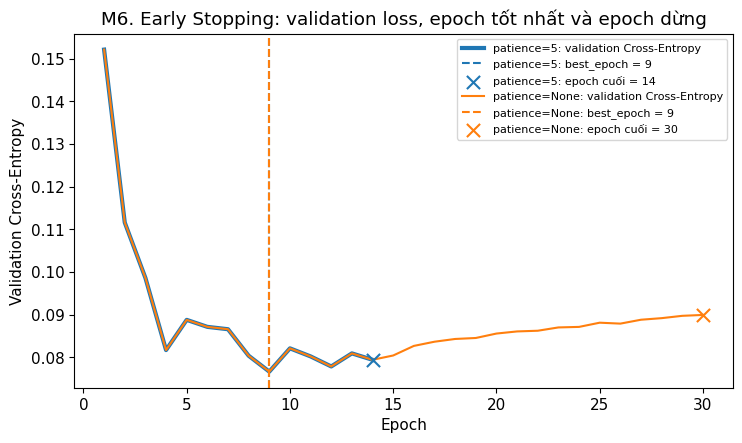

In [64]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for (name, model), color, width in zip(es_models.items(), ("tab:blue", "tab:orange"), (3, 1.5)):
  val_loss = model.history_["val_loss"]
  ax.plot(np.arange(1, len(val_loss) + 1), val_loss, color=color, linewidth=width, label=f"{name}: validation Cross-Entropy")
  ax.axvline(model.best_epoch_, color=color, linestyle="--", label=f"{name}: best_epoch = {model.best_epoch_}")
  ax.scatter([model.epochs_trained_], [val_loss[-1]], color=color, marker="x", s=90, zorder=3,
             label=f"{name}: epoch cuối = {model.epochs_trained_}")

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Cross-Entropy")
ax.set_title("M6. Early Stopping: validation loss, epoch tốt nhất và epoch dừng")
ax.legend(fontsize=8)
save_figure(fig, "mlp_early_stopping")

### 8.7.1 Early Stopping và khôi phục trọng số (M6)

Với `patience=5`, mô hình dừng sau **14 epoch**, trong khi cấu hình `patience=None` chạy đủ **30 epoch**. Cả hai trường hợp có truyền validation đều khôi phục trọng số ở **epoch 9** và đạt Accuracy validation **97,71%** sau khi kết thúc `fit()`. Cột `restored_best_weights=True` xác nhận loss validation sau khi khôi phục khớp với loss tốt nhất đã ghi nhận trong phạm vi sai số kiểm tra. Kết quả minh họa khả năng giảm số epoch huấn luyện mà vẫn giữ kết quả của cấu hình này; không chứng minh Early Stopping luôn loại bỏ overfitting do nó không trực tiếp cải thiện thuật toán mô hình.


## 8.8 M7. L2 Weight Decay

`weight_decay` trong `[0, 1e-4, 1e-3]`, các tham số khác giữ như baseline (10 epoch, không truyền validation vào `fit`). Cross-Entropy của train và validation được tính lại bằng `mlp_cross_entropy` để cùng định nghĩa; `train_loss_with_l2` là giá trị cuối của `history_["train_loss"]` (đã gồm L2).

In [65]:
MLP_WEIGHT_DECAYS = [0, 1e-4, 1e-3]
rows = []
for weight_decay in MLP_WEIGHT_DECAYS:
  model = make_mlp(weight_decay=weight_decay)
  row = summarize_experiment(model, {"weight_decay": weight_decay})
  row["train_ce"] = mlp_cross_entropy(model, X_train, y_train)
  row["val_ce"] = mlp_cross_entropy(model, X_val, y_val)
  row["train_loss_with_l2"] = model.history_["train_loss"][-1]
  rows.append(row)

df_mlp_wd = pd.DataFrame(rows)
best_row_wd = df_mlp_wd.loc[df_mlp_wd["val_acc"].idxmax()]
save_table(df_mlp_wd, "mlp_weight_decay")

[CACHE SAVED] MLPFromScratch / experiment (26.6s)
[CACHE SAVED] MLPFromScratch / experiment (25.8s)
[CACHE SAVED] MLPFromScratch / experiment (26.9s)


,weight_decay,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s,train_only_time_s,eval_time_s,diverged,train_ce,val_ce,train_loss_with_l2
0,0.0000,0.9989,0.9772,0.9989,0.9770,0.0217,26.6018,0.1343,21.6160,4.9833,False,0.0054,0.0821,0.0054
1,0.0001,0.9982,0.9769,0.9982,0.9767,0.0213,25.8112,0.0827,21.0109,4.7965,False,0.0088,0.0760,0.0525
2,0.0010,0.9905,0.9770,0.9905,0.9768,0.0135,26.8582,0.1002,21.9592,4.8966,False,0.0425,0.0802,0.1417


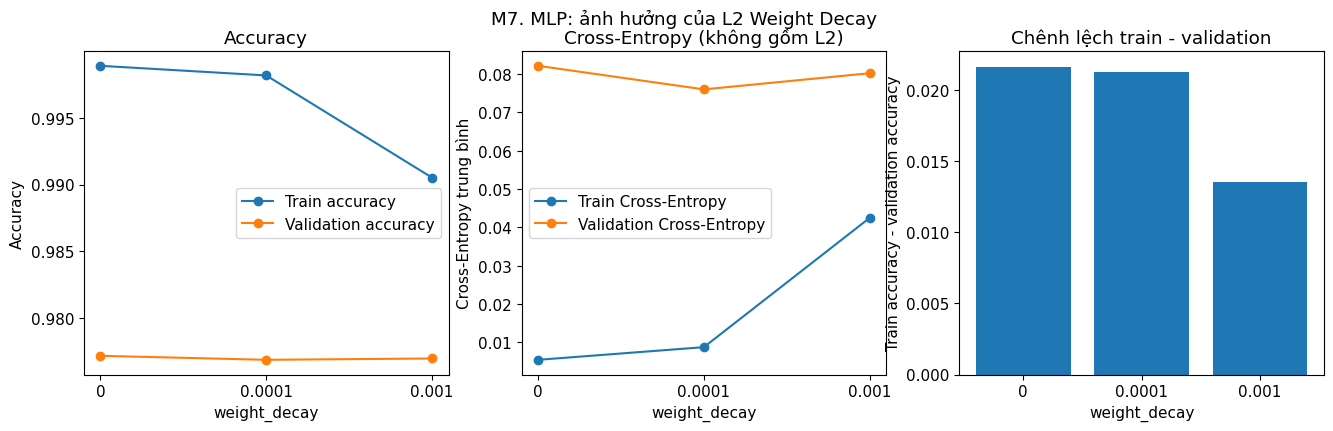

In [66]:
positions = np.arange(len(MLP_WEIGHT_DECAYS))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(positions, df_mlp_wd["train_acc"], marker="o", label="Train accuracy")
axes[0].plot(positions, df_mlp_wd["val_acc"], marker="o", label="Validation accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(positions, df_mlp_wd["train_ce"], marker="o", label="Train Cross-Entropy")
axes[1].plot(positions, df_mlp_wd["val_ce"], marker="o", label="Validation Cross-Entropy")
axes[1].set_ylabel("Cross-Entropy trung bình")
axes[1].set_title("Cross-Entropy (không gồm L2)")
axes[1].legend()

axes[2].bar(positions, df_mlp_wd["gap_acc"])
axes[2].set_ylabel("Train accuracy - validation accuracy")
axes[2].set_title("Chênh lệch train - validation")
for ax in axes:
  ax.set_xticks(positions)
  ax.set_xticklabels([str(w) for w in MLP_WEIGHT_DECAYS])
  ax.set_xlabel("weight_decay")

fig.suptitle("M7. MLP: ảnh hưởng của L2 Weight Decay")
save_figure(fig, "mlp_weight_decay")

### 8.8.1 Ảnh hưởng của L2 Weight Decay (M7)

Với `weight_decay=0`, chênh lệch Accuracy train–validation là **0,0217**; khi tăng lên **0,001**, chênh lệch giảm còn **0,0135**. Tuy nhiên, Accuracy validation lần lượt là **97,72%** và **97,70%**. Do đó, L2 làm giảm chênh lệch giữa hai tập trong thí nghiệm này nhưng không cải thiện Accuracy validation. Cấu hình cuối chọn `weight_decay=0`.


## 8.9 Chọn cấu hình MLP cuối

Mỗi siêu tham số lấy từ cấu hình có validation accuracy cao nhất trong thí nghiệm tương ứng (M2, M3, M4, M5, M7). Model cuối huấn luyện trên 50.000 ảnh train, dùng validation cho Early Stopping (`patience=FINAL_PATIENCE`, `max_epochs=FINAL_MAX_EPOCHS`). Chưa dùng test.

In [67]:
selection = [
    ("hidden_sizes", ARCHS[best_row_arch["architecture"]], "M4", best_row_arch),
    ("lr", float(best_row_lrmom["lr"]), "M2", best_row_lrmom),
    ("momentum", float(best_row_lrmom["momentum"]), "M2", best_row_lrmom),
    ("batch_size", int(best_row_batch["batch_size"]), "M3", best_row_batch),
    ("dropout", float(best_row_dropout["dropout"]), "M5", best_row_dropout),
    ("weight_decay", float(best_row_wd["weight_decay"]), "M7", best_row_wd),
]
df_mlp_selection = pd.DataFrame([
    {"hyperparameter": name, "value": str(value), "chosen_in": exp, "val_acc_in_experiment": float(row["val_acc"])}
    for name, value, exp, row in selection
])
save_table(df_mlp_selection, "mlp_selected_config")

config_mlp = {name: value for name, value, _, _ in selection}
config_mlp.update(max_epochs=FINAL_MAX_EPOCHS, patience=FINAL_PATIENCE, seed=SEED, eval_batch_size=MLP_BASE["eval_batch_size"])
config_mlp

{'hidden_sizes': [1024],
 'lr': 0.1,
 'momentum': 0.9,
 'batch_size': 64,
 'dropout': 0.2,
 'weight_decay': 0.0,
 'max_epochs': 30,
 'patience': 5,
 'seed': 42,
 'eval_batch_size': 1024}

In [68]:
mlp_final = MLPFromScratch(**config_mlp)
mlp_final_fit_time = fit_model_cached(mlp_final, VAL_ARGS, tag="mlp_final")
if mlp_final.diverged_:
  raise RuntimeError("MLP cuối bị phân kỳ; cần điều chỉnh hyperparameter trước khi tiếp tục.")
if mlp_final.epochs_trained_ <= 0 or mlp_final.best_epoch_ is None:
  raise RuntimeError("MLP cuối chưa có epoch hợp lệ hoặc chưa chọn được best_epoch_.")

df_mlp_final = pd.DataFrame([{
    "best_epoch": mlp_final.best_epoch_, "epochs_trained": mlp_final.epochs_trained_,
    "stopped_early": mlp_final.stopped_early_, "fit_time_s": mlp_final_fit_time,
    "n_params": n_parameters(mlp_final),
    "val_ce_after_fit": mlp_cross_entropy(mlp_final, X_val, y_val),
    "val_acc": evaluate_model(mlp_final, X_val, y_val)["accuracy"],
    "train_only_time_s": mlp_final.fit_time_, "eval_time_s": mlp_final.eval_time_,
    "diverged": bool(mlp_final.diverged_),
}])
save_table(df_mlp_final, "mlp_final_fit")
save_table(history_table(mlp_final.history_), "mlp_final_history")

[CACHE SAVED] MLPFromScratch / mlp_final (362.8s)


,epoch,train_loss,train_acc,val_loss,val_acc,epoch_time
0,1,0.1187,0.9619,0.1459,0.9540,9.9883
1,2,0.0569,0.9822,0.0900,0.9715,13.5314
2,3,0.0433,0.9865,0.0910,0.9704,15.0090
3,4,0.0335,0.9890,0.0839,0.9758,16.6055
4,5,0.0278,0.9904,0.0856,0.9744,16.9297
5,6,0.0238,0.9923,0.0902,0.9737,12.2753
6,7,0.0141,0.9955,0.0787,0.9784,12.8834
7,8,0.0106,0.9971,0.0784,0.9792,12.8418
8,9,0.0136,0.9957,0.0905,0.9777,14.1135
9,10,0.0062,0.9982,0.0778,0.9799,12.8344


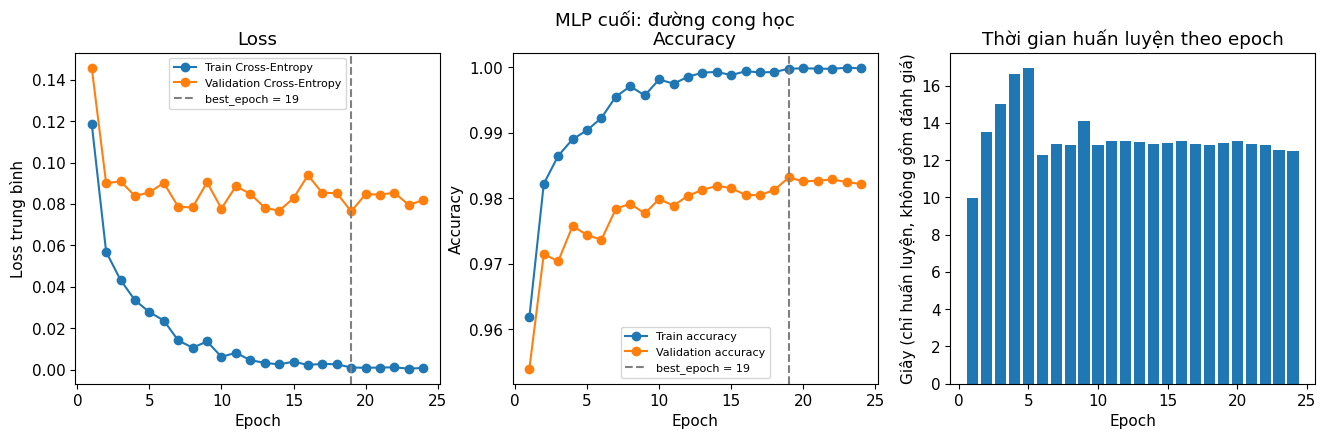

In [69]:
plot_history(mlp_final.history_, mlp_final.best_epoch_, config_mlp["weight_decay"],
             "MLP cuối: đường cong học", "mlp_final_curve")

### 8.9.1 Cấu hình MLP được chọn

Cấu hình cuối sử dụng **một lớp ẩn gồm 1.024 neuron** (`784–1024–10`), `lr=0.1`, `momentum=0.9`, `batch_size=64`, `dropout=0.2`, `weight_decay=0`, `max_epochs=30` và `patience=5`. Validation loss thấp nhất được ghi nhận tại **epoch 19**; huấn luyện dừng sau **24 epoch** và khôi phục trọng số tương ứng epoch 19. Cấu hình được hình thành bằng cách kết hợp các giá trị tốt nhất trong những thí nghiệm riêng lẻ; chưa thực hiện tìm kiếm toàn diện trên mọi tổ hợp siêu tham số.


# 9. Random Forest: cấu hình cơ sở và thí nghiệm

## 9.1 Cấu hình cơ sở `RandomForestFromScratch(n_estimators=50, max_depth=15, max_features="sqrt", seed=42)`

Mô hình sử dụng bootstrap và biểu quyết đa số do nhóm cài đặt; các cây cơ sở được tạo bằng `DecisionTreeClassifier` của scikit-learn.


In [70]:
RF_DEPTH = 15
rf_baseline = RandomForestFromScratch(n_estimators=50, max_depth=RF_DEPTH, max_features="sqrt", seed=SEED)
row_rf = summarize_experiment(rf_baseline, {"model": "Random Forest", "n_estimators": 50, "max_depth": RF_DEPTH})
save_table(pd.DataFrame([row_rf]), "forest_baseline")

[CACHE SAVED] RandomForestFromScratch / experiment (31.5s)


,model,n_estimators,max_depth,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s
0,Random Forest,50,15,0.9967,0.9594,0.9967,0.9590,0.0373,31.4912,0.3988


### 9.1.1 Kết quả Random Forest cơ sở

Random Forest với **50 cây**, độ sâu tối đa **15** đạt Accuracy validation **95,94%**. Chênh lệch Accuracy train–validation là **3,73 điểm phần trăm**. Bagging có thể giúp giảm phương sai so với cây đơn, nhưng mức độ tác động cần được đối chiếu trực tiếp ở mục 9.3.


## 9.2 R1. Số cây `n_estimators`

Thời gian dự đoán đo trên validation. Không dùng test.

In [71]:
RF_TREES = [10, 30, 50]
df_rf_trees = pd.DataFrame([
  summarize_experiment(
        RandomForestFromScratch(n_estimators=n, max_depth=RF_DEPTH, max_features="sqrt", seed=SEED),
        {"n_estimators": n})
  for n in RF_TREES
])

best_row_rf = df_rf_trees.loc[df_rf_trees["val_acc"].idxmax()]
best_n_estimators = int(best_row_rf["n_estimators"])
print("n_estimators tốt nhất theo validation accuracy:", best_n_estimators)
save_table(df_rf_trees, "forest_n_estimators")

[CACHE SAVED] RandomForestFromScratch / experiment (7.1s)
[CACHE SAVED] RandomForestFromScratch / experiment (18.7s)
[CACHE HIT] RandomForestFromScratch / experiment
n_estimators tốt nhất theo validation accuracy: 50


,n_estimators,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s
0,10,0.9919,0.9405,0.9919,0.9396,0.0514,7.0606,0.1137
1,30,0.9958,0.9572,0.9959,0.9567,0.0386,18.6521,0.2520
2,50,0.9967,0.9594,0.9967,0.9590,0.0373,31.4912,0.4073


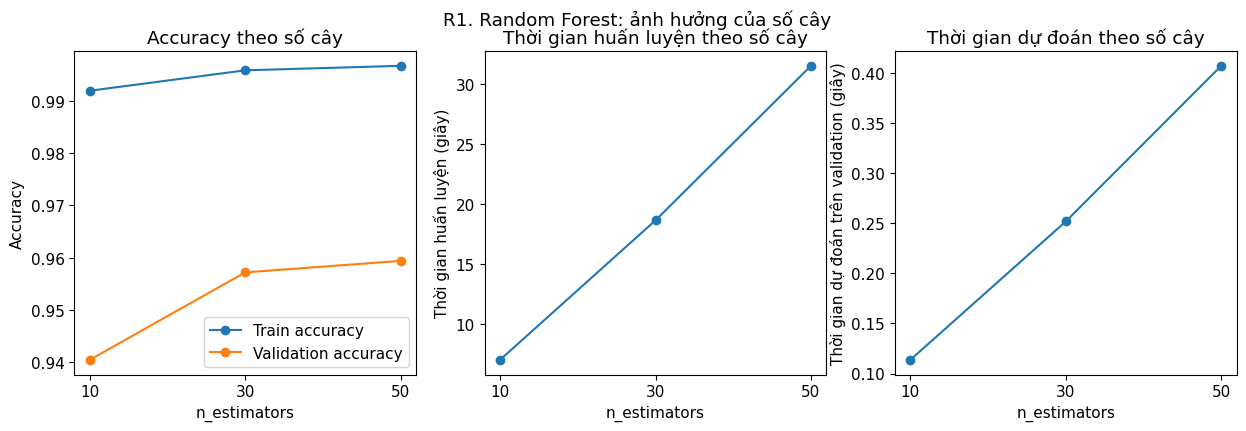

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(df_rf_trees["n_estimators"], df_rf_trees["train_acc"], marker="o", label="Train accuracy")
axes[0].plot(df_rf_trees["n_estimators"], df_rf_trees["val_acc"], marker="o", label="Validation accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy theo số cây")
axes[0].legend()

axes[1].plot(df_rf_trees["n_estimators"], df_rf_trees["fit_time_s"], marker="o")
axes[1].set_ylabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Thời gian huấn luyện theo số cây")

axes[2].plot(df_rf_trees["n_estimators"], df_rf_trees["val_predict_time_s"], marker="o")
axes[2].set_ylabel("Thời gian dự đoán trên validation (giây)")
axes[2].set_title("Thời gian dự đoán theo số cây")
for ax in axes:
  ax.set_xticks(RF_TREES)
  ax.set_xlabel("n_estimators")

fig.suptitle("R1. Random Forest: ảnh hưởng của số cây")
save_figure(fig, "forest_n_estimators")

### 9.2.1 Ảnh hưởng của số cây (R1)

Khi tăng số cây từ **10** lên **30** và **50**, Accuracy validation lần lượt là **94,05%**, **95,72%** và **95,94%**. Thời gian huấn luyện tăng theo số cây, nhưng thời gian dự đoán đo được không tăng tuyến tính hoàn toàn. Mức cải thiện Accuracy từ 30 lên 50 cây nhỏ hơn so với từ 10 lên 30 cây; **50 cây** được chọn vì có Accuracy validation cao nhất trong các cấu hình đã thử.


## 9.3 R2. Decision Tree đơn và Random Forest

Cây đơn là `sklearn.tree.DecisionTreeClassifier` với cùng `max_depth` và `seed`. Hàng Random Forest lấy từ baseline ở mục 9.1.

In [73]:
tree_single = DecisionTreeClassifier(max_depth=RF_DEPTH, random_state=SEED)
row_tree = summarize_experiment(tree_single, {"model": "Decision Tree (sklearn, cây đơn)", "n_estimators": 1, "max_depth": RF_DEPTH})
row_forest_ref = {**row_rf, "model": "RandomForestFromScratch (50 cây)"}
df_tree_vs_forest = pd.DataFrame([row_tree, row_forest_ref])
save_table(df_tree_vs_forest, "forest_tree_vs_forest")

[CACHE SAVED] DecisionTreeClassifier / experiment (14.4s)


,model,n_estimators,max_depth,train_acc,val_acc,train_f1,val_f1,gap_acc,fit_time_s,val_predict_time_s
0,"Decision Tree (sklearn, cây đơn)",1,15,0.9845,0.8738,0.9844,0.8721,0.1107,14.4243,0.0114
1,RandomForestFromScratch (50 cây),50,15,0.9967,0.9594,0.9967,0.9590,0.0373,31.4912,0.3988


### 9.3.1 So sánh cây quyết định đơn và Random Forest (R2)

Cây đơn có Accuracy train **98,45%** và validation **87,38%**, chênh lệch **11,07 điểm phần trăm**. Random Forest 50 cây đạt **99,67%** trên train và **95,94%** trên validation, chênh lệch **3,73 điểm phần trăm**.

## 9.4 R3. Độ quan trọng đặc trưng

Độ quan trọng là trung bình `feature_importances_` của các cây trong Forest baseline (mục 9.1), đối chiếu với ảnh trung bình và độ lệch chuẩn pixel của EDA (E3).

In [74]:
importance = np.mean([tree.feature_importances_ for tree in rf_baseline.trees], axis=0)
train_mean_image = X_train.mean(axis=0)

top = np.argsort(importance)[::-1][:10]
df_importance_top = pd.DataFrame({"pixel_index": top, "row": top // 28, "col": top % 28, "importance": importance[top]})
df_importance_corr = pd.DataFrame([{
    "corr_importance_pixel_std": np.corrcoef(importance, pixel_std)[0, 1],
    "corr_importance_mean_image": np.corrcoef(importance, train_mean_image)[0, 1],
    "n_pixels_importance_zero": int((importance == 0).sum()),
}])
save_table(df_importance_top, "forest_feature_importance_top10")
save_table(df_importance_corr, "forest_feature_importance_corr")

,corr_importance_pixel_std,corr_importance_mean_image,n_pixels_importance_zero
0,0.7966,0.8231,147


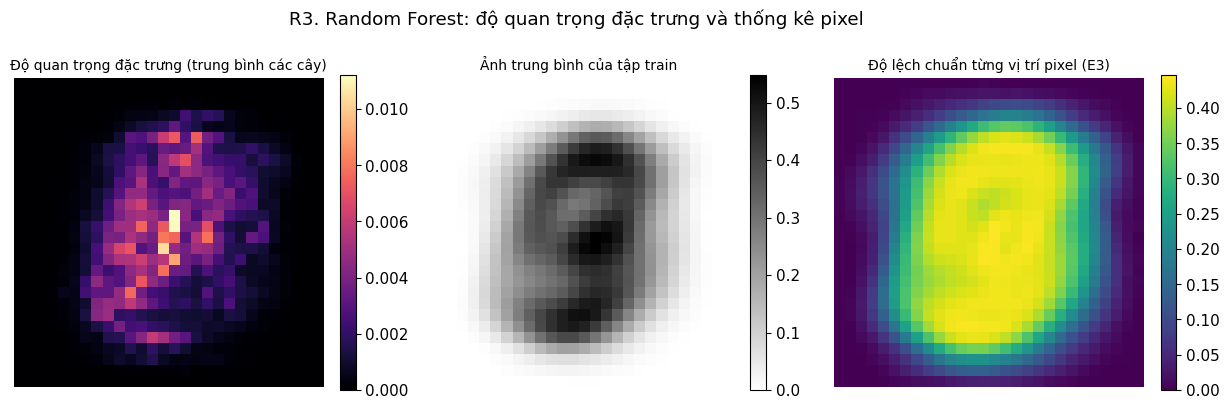

In [75]:
panels = [(importance, "Độ quan trọng đặc trưng (trung bình các cây)", "magma"),
          (train_mean_image, "Ảnh trung bình của tập train", "gray_r"),
          (pixel_std, "Độ lệch chuẩn từng vị trí pixel (E3)", "viridis")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

for ax, (data, title, cmap) in zip(axes, panels):
  im = ax.imshow(data.reshape(28, 28), cmap=cmap)
  ax.set_title(title, fontsize=10)
  ax.axis("off")
  fig.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("R3. Random Forest: độ quan trọng đặc trưng và thống kê pixel")
save_figure(fig, "forest_feature_importance")

### 9.4.1 Trực quan hóa độ quan trọng đặc trưng (R3)

Độ quan trọng đặc trưng có xu hướng tập trung ở những vùng xuất hiện nét chữ, tương ứng với các vị trí có biến thiên pixel lớn. Tương quan Pearson giữa độ quan trọng và độ lệch chuẩn pixel là khoảng **0,7966**; với ảnh trung bình là khoảng **0,8231**. Có **147 pixel** có độ quan trọng bằng 0 theo các cây được huấn luyện, nhưng con số này **khác** với **71 vị trí có phương sai bằng 0** trong EDA; không nên mô tả hai tập vị trí là trùng khớp hoàn toàn.


## 9.5 Chọn số cây cuối

`n_estimators` cuối là giá trị có validation accuracy cao nhất ở R1; giữ Hard Voting.

In [76]:
save_table(pd.DataFrame([{"model": "Random Forest", "n_estimators": best_n_estimators, "max_depth": RF_DEPTH,
                          "max_features": "sqrt", "voting": "hard (majority)", "seed": SEED,
                          "val_acc": float(best_row_rf["val_acc"]), "val_f1": float(best_row_rf["val_f1"])}]),
           "forest_selected_config")

,model,n_estimators,max_depth,max_features,voting,seed,val_acc,val_f1
0,Random Forest,50,15,sqrt,hard (majority),42,0.9594,0.9590


### 9.5.1 Cấu hình Random Forest được chọn

Cấu hình cuối sử dụng **50 cây**, độ sâu tối đa **15**, `max_features="sqrt"` và cơ chế **hard voting**. Các giá trị này được lựa chọn theo kết quả validation trong phạm vi thí nghiệm.


# 10. Đánh giá cuối trên train, validation và test

Các siêu tham số được lựa chọn từ kết quả validation ở mục 6–9. Từ mục này, tập test mới được sử dụng để đánh giá hiệu năng cuối cùng.

## 10.1 Cấu hình cuối và huấn luyện

Naive Bayes, Softmax Regression và Random Forest được huấn luyện trên 50.000 ảnh train với cấu hình đã chọn. MLP sử dụng mô hình huấn luyện ở mục 8.9. Thời gian `fit()` của MLP bao gồm cả đánh giá train/validation sau từng epoch; hai thành phần thời gian được lưu riêng trong `results/mlp_final_fit.csv`.


In [77]:
config_nb = {"alpha": best_alpha}
config_softmax = dict(lr=best_lr, max_epochs=SM_EPOCHS, batch_size=SM_BATCH, lam=best_lam, seed=SEED)
config_forest = dict(n_estimators=best_n_estimators, max_depth=RF_DEPTH, max_features="sqrt", seed=SEED)
final_configs = {"Naive Bayes": config_nb, "Softmax Regression": config_softmax,
                 "MLP": config_mlp, "Random Forest": config_forest}

final_models = {
    "Naive Bayes": NaiveBayes(**config_nb),
    "Softmax Regression": SoftmaxRegression(**config_softmax),
    "Random Forest": RandomForestFromScratch(**config_forest),
}
fit_times = {}
for name, model in final_models.items():
    fit_times[name] = fit_model_cached(model, (X_train, y_train), tag="final")
final_models["MLP"] = mlp_final
fit_times["MLP"] = mlp_final_fit_time
final_models = {name: final_models[name] for name in MODEL_NAMES}

df_final_config = pd.DataFrame([
    {"model": name, "config": json.dumps(config, ensure_ascii=False), "fit_time_s": fit_times[name]}
    for name, config in final_configs.items()
])
with open(RESULT_DIR / "final_config.json", "w", encoding="utf-8") as f:
  json.dump(final_configs, f, ensure_ascii=False, indent=2)
save_table(df_final_config, "final_config")

[CACHE SAVED] NaiveBayes / final (0.1s)
[CACHE SAVED] SoftmaxRegression / final (26.3s)
[CACHE SAVED] RandomForestFromScratch / final (31.5s)


,model,config,fit_time_s
0,Naive Bayes,"{""alpha"": 0.001}",0.0606
1,Softmax Regression,"{""lr"": 0.1, ""max_epochs"": 20, ""batch_size"": 12...",26.3259
2,MLP,"{""hidden_sizes"": [1024], ""lr"": 0.1, ""momentum""...",362.8098
3,Random Forest,"{""n_estimators"": 50, ""max_depth"": 15, ""max_fea...",31.5295


### 10.1.1 Các siêu tham số được sử dụng

- **Multinomial Naive Bayes:** $\alpha=0{,}001$.
- **Softmax Regression:** learning rate **0,1**, L2 **0**, **20 epoch**, batch size **128**.
- **MLP:** một lớp ẩn **[1024]**, learning rate **0,1**, Momentum **0,9**, batch size **64**, Dropout **0,2**, Early Stopping với `patience=5`.
- **Random Forest:** **50 cây**, độ sâu tối đa **15**, `max_features="sqrt"`, hard voting.


## 10.2 K1. Bảng metrics của 4 model trên 3 tập

Metrics tính bằng `src.metrics.compute_classification_metrics`; Precision, Recall và F1 là trung bình macro. Kết quả được đối chiếu với `sklearn.metrics` ở cell sau.

In [78]:
final_metrics, final_preds, predict_time_test = {}, {}, {}
for name in MODEL_NAMES:
  model = final_models[name]
  for split, X, y in zip(SPLIT_NAMES, FEATURES[name], LABELS):
    start = time.perf_counter()
    y_pred = model.predict(X)
    elapsed = time.perf_counter() - start
    final_metrics[(name, split)] = compute_classification_metrics(y, y_pred)
    final_preds[(name, split)] = y_pred
    if split == "test":
      predict_time_test[name] = elapsed

df_k1 = pd.DataFrame([
    {"Model": name, "Split": split, "Accuracy": m["accuracy"], "Precision_macro": m["precision_macro"],
     "Recall_macro": m["recall_macro"], "F1_macro": m["f1_macro"]}
    for (name, split), m in final_metrics.items()
])
save_table(df_k1, "final_metrics")

,Model,Split,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Naive Bayes,train,0.8243,0.8315,0.8214,0.8231
1,Naive Bayes,validation,0.8257,0.8317,0.8220,0.8237
2,Naive Bayes,test,0.8361,0.8430,0.8330,0.8346
3,Softmax Regression,train,0.9241,0.9234,0.9230,0.9231
4,Softmax Regression,validation,0.9187,0.9179,0.9174,0.9174
5,Softmax Regression,test,0.9222,0.9214,0.9211,0.9210
6,MLP,train,0.9998,0.9998,0.9998,0.9998
7,MLP,validation,0.9832,0.9832,0.9829,0.9831
8,MLP,test,0.9847,0.9848,0.9845,0.9846
9,Random Forest,train,0.9967,0.9968,0.9966,0.9967


In [79]:
check_rows = []
for (name, split), m in final_metrics.items():
  y = LABELS[SPLIT_NAMES.index(split)]
  y_pred = final_preds[(name, split)]
  check_rows.append({
      "Model": name, "Split": split,
      "diff_accuracy": abs(m["accuracy"] - accuracy_score(y, y_pred)),
      "diff_precision_macro": abs(m["precision_macro"] - precision_score(y, y_pred, average="macro", zero_division=0)),
      "diff_recall_macro": abs(m["recall_macro"] - recall_score(y, y_pred, average="macro", zero_division=0)),
      "diff_f1_macro": abs(m["f1_macro"] - f1_score(y, y_pred, average="macro", zero_division=0)),
      "confusion_matrix_equal": bool(np.array_equal(m["confusion_matrix"], confusion_matrix(y, y_pred, labels=np.arange(10)))),
    })
save_table(pd.DataFrame(check_rows), "final_metrics_sklearn_check")

,Model,Split,diff_accuracy,diff_precision_macro,diff_recall_macro,diff_f1_macro,confusion_matrix_equal
0,Naive Bayes,train,0.0000,0.0000,0.0000,0.0000,True
1,Naive Bayes,validation,0.0000,0.0000,0.0000,0.0000,True
2,Naive Bayes,test,0.0000,0.0000,0.0000,0.0000,True
3,Softmax Regression,train,0.0000,0.0000,0.0000,0.0000,True
4,Softmax Regression,validation,0.0000,0.0000,0.0000,0.0000,True
5,Softmax Regression,test,0.0000,0.0000,0.0000,0.0000,True
6,MLP,train,0.0000,0.0000,0.0000,0.0000,True
7,MLP,validation,0.0000,0.0000,0.0000,0.0000,True
8,MLP,test,0.0000,0.0000,0.0000,0.0000,True
9,Random Forest,train,0.0000,0.0000,0.0000,0.0000,True


### 10.2.1 Hiệu năng trên ba tập dữ liệu (K1)

Trên tập test, Accuracy của bốn mô hình lần lượt là **83,61%** (Naive Bayes), **92,22%** (Softmax Regression), **98,47%** (MLP) và **96,10%** (Random Forest). MLP đạt Accuracy cao nhất trong bốn mô hình khảo sát. Chênh lệch train–validation của MLP là **1,66 điểm phần trăm**, trong khi Random Forest là **3,73 điểm phần trăm**; vì vậy không nên mô tả các mô hình là hoàn toàn không overfitting. Các kết luận chỉ áp dụng cho dữ liệu và cấu hình được thử.


## 10.3 K2. Ma trận nhầm lẫn

Mười hai ma trận nhầm lẫn (4 model x 3 tập) được lưu trong `results/confusion_matrices.npz`. Hình vẽ bốn ma trận trên tập test; hàng là nhãn thật, cột là nhãn dự đoán.

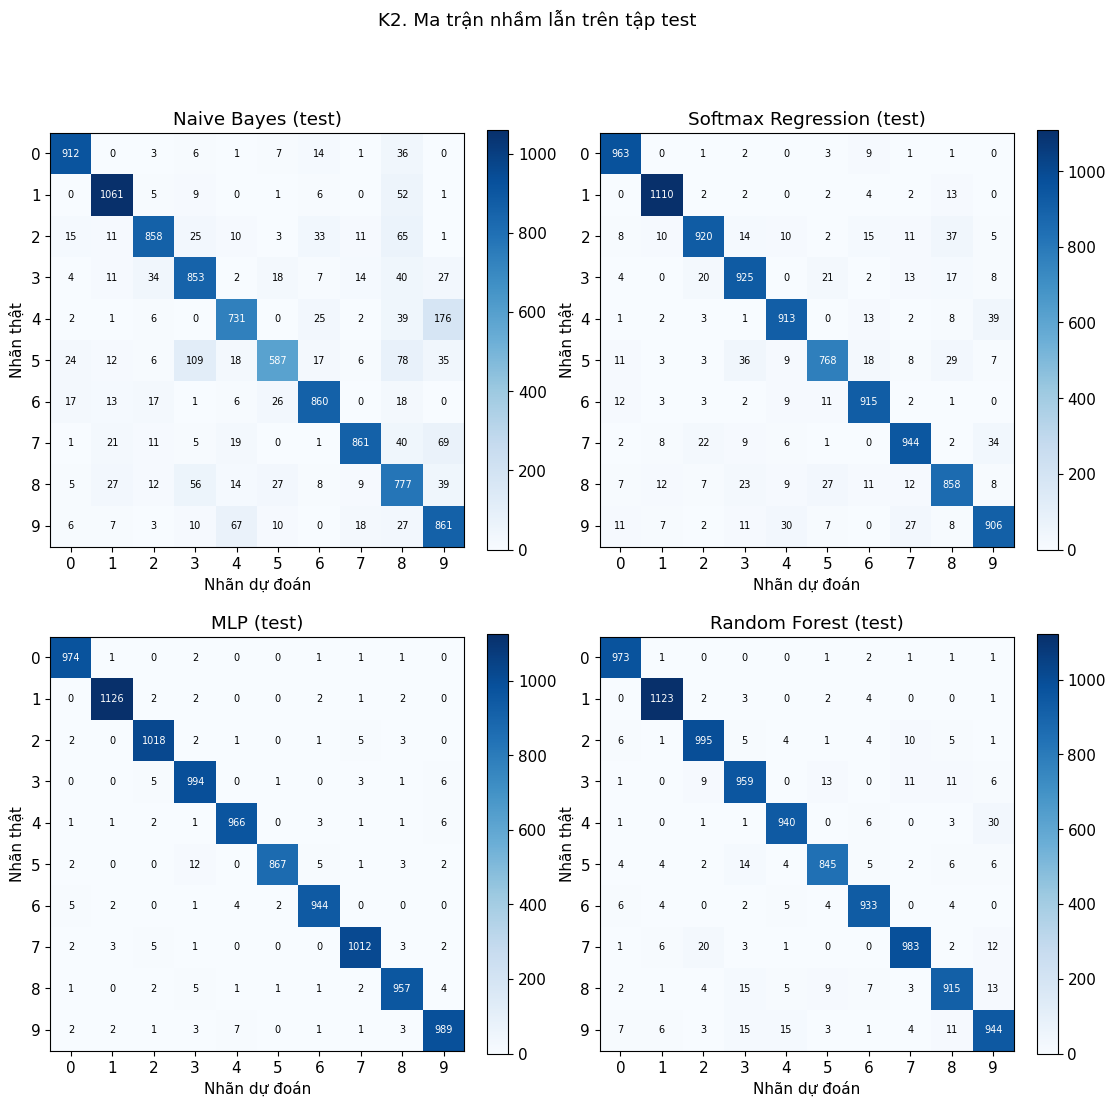

In [80]:
def slug(name):
  return name.lower().replace(" ", "_")

np.savez(RESULT_DIR / "confusion_matrices.npz",
         **{f"{slug(name)}__{split}": m["confusion_matrix"] for (name, split), m in final_metrics.items()})

def plot_confusion(fig, ax, cm, title):
  im = ax.imshow(cm, cmap="Blues")
  threshold = cm.max() / 2
  for i in range(10):
    for j in range(10):
      ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
              color="white" if cm[i, j] > threshold else "black")
  ax.set_xticks(range(10))
  ax.set_yticks(range(10))
  ax.set_xlabel("Nhãn dự đoán")
  ax.set_ylabel("Nhãn thật")
  ax.set_title(title)
  fig.colorbar(im, ax=ax, fraction=0.046)


fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for ax, name in zip(axes.ravel(), MODEL_NAMES):
  plot_confusion(fig, ax, final_metrics[(name, "test")]["confusion_matrix"], f"{name} (test)")
fig.suptitle("K2. Ma trận nhầm lẫn trên tập test")
save_figure(fig, "confusion_matrices_test")

### 10.3.1 Diễn giải ma trận nhầm lẫn (K2)

Ma trận nhầm lẫn cho biết số dự đoán đúng và sai theo từng chữ số, với **hàng là nhãn thật** và **cột là nhãn dự đoán**. Các lớp 0 và 1 nhìn chung có Recall cao, trong khi lớp 5 thường khó phân loại hơn, đặc biệt đối với Naive Bayes.


## 10.4 K3. Các cặp chữ số bị nhầm nhiều nhất

Với mỗi model, số lỗi của cặp `(a, b)` là tổng hai chiều `a -> b` và `b -> a` trên ma trận nhầm lẫn của tập test; mỗi cặp chỉ đếm một lần. Cột `in_eda_closest_pairs` cho biết cặp đó có nằm trong ba cặp ảnh trung bình gần nhau nhất ở E5 hay không.

In [81]:
def top_confused_pairs(cm, k=3):
  pairs = [(a, b, cm[a, b], cm[b, a]) for a in range(10) for b in range(a + 1, 10)]
  return sorted(pairs, key=lambda p: p[2] + p[3], reverse=True)[:k]

rows = []
for name in MODEL_NAMES:
  cm = final_metrics[(name, "test")]["confusion_matrix"]
  for rank, (a, b, a_to_b, b_to_a) in enumerate(top_confused_pairs(cm), start=1):
    rows.append({"Model": name, "rank": rank, "digit_a": a, "digit_b": b, "errors_a_to_b": a_to_b,
                 "errors_b_to_a": b_to_a, "total_errors": a_to_b + b_to_a,
                 "in_eda_closest_pairs": (a, b) in eda_pair_set})
df_k3 = pd.DataFrame(rows)
save_table(df_k3, "confusion_pairs")

,Model,rank,digit_a,digit_b,errors_a_to_b,errors_b_to_a,total_errors,in_eda_closest_pairs
0,Naive Bayes,1,4,9,176,67,243,True
1,Naive Bayes,2,3,5,18,109,127,False
2,Naive Bayes,3,5,8,78,27,105,True
3,Softmax Regression,1,4,9,39,30,69,True
4,Softmax Regression,2,7,9,34,27,61,True
5,Softmax Regression,3,3,5,21,36,57,False
6,MLP,1,3,5,1,12,13,False
7,MLP,2,4,9,6,7,13,True
8,MLP,3,2,7,5,5,10,False
9,Random Forest,1,4,9,30,15,45,True


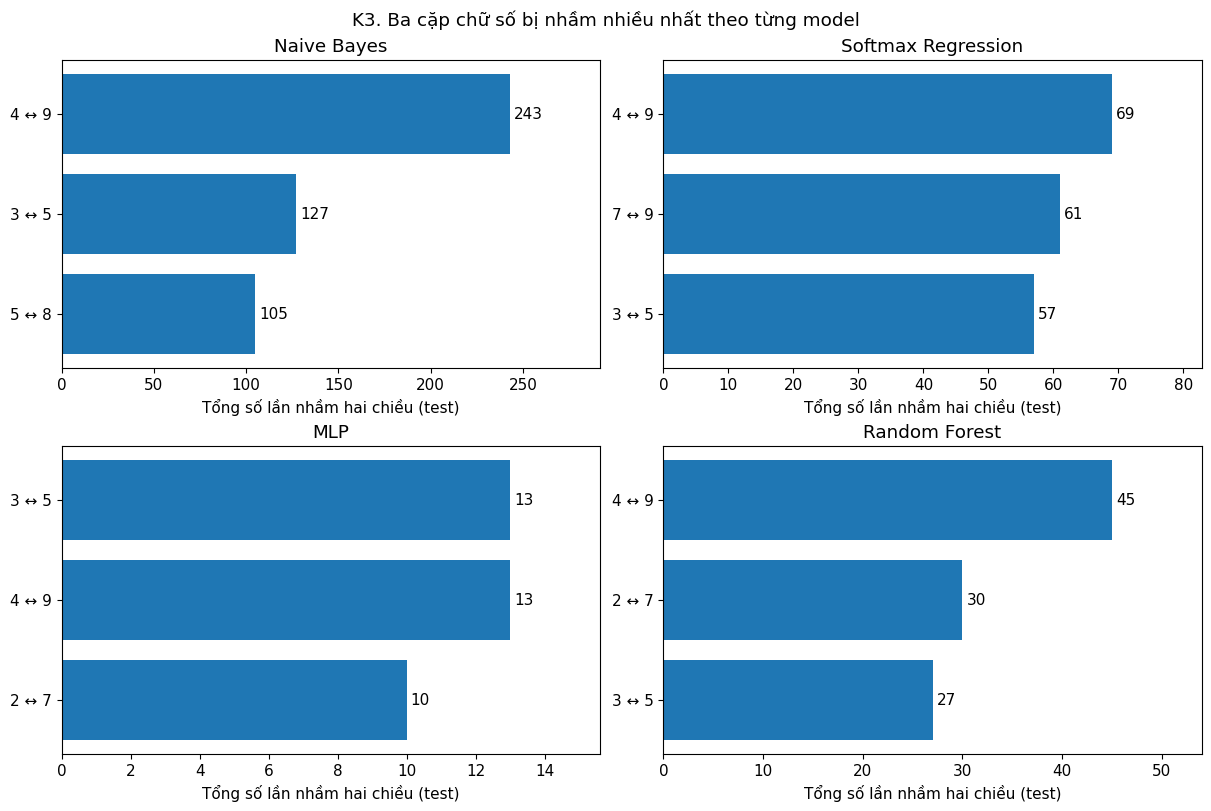

In [82]:
# K3 bổ sung: trực quan hóa ba cặp chữ số bị nhầm nhiều nhất cho từng model.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, name in zip(axes.ravel(), MODEL_NAMES):
  sub = df_k3[df_k3["Model"] == name].sort_values("rank")
  labels = [f"{int(a)} ↔ {int(b)}" for a, b in zip(sub["digit_a"], sub["digit_b"])]
  bars = ax.barh(labels, sub["total_errors"].to_numpy())
  ax.invert_yaxis()
  ax.bar_label(bars, padding=3)
  ax.set_xlim(0, max(1, float(sub["total_errors"].max())) * 1.2)
  ax.set_xlabel("Tổng số lần nhầm hai chiều (test)")
  ax.set_title(name)

fig.suptitle("K3. Ba cặp chữ số bị nhầm nhiều nhất theo từng model")
save_figure(fig, "confusion_top_pairs")


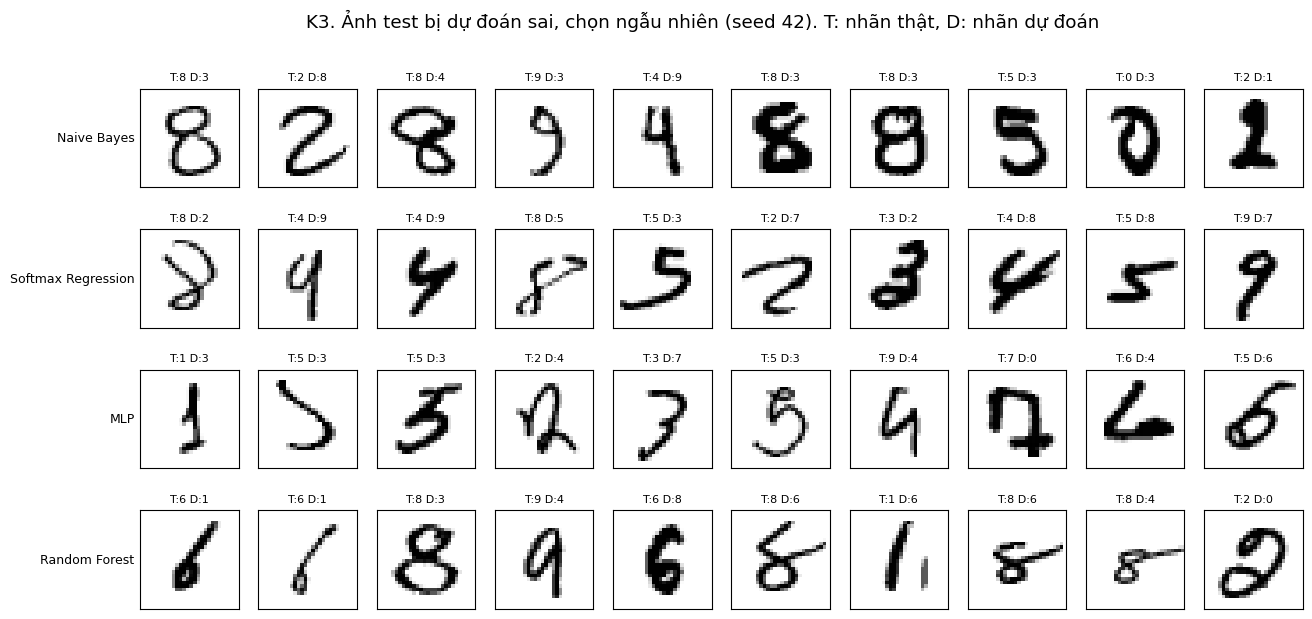

In [83]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 10, figsize=(15, 7))
for r, name in enumerate(MODEL_NAMES):
  y_pred = final_preds[(name, "test")]
  wrong = np.where(y_pred != y_test)[0]
  picked = np.sort(rng.choice(wrong, size=10, replace=False))
  for c, i in enumerate(picked):
    axes[r, c].imshow(X_test[i].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    axes[r, c].set_title(f"T:{y_test[i]} D:{y_pred[i]}", fontsize=8)
    axes[r, c].set_xticks([])
    axes[r, c].set_yticks([])
  axes[r, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)

fig.suptitle("K3. Ảnh test bị dự đoán sai, chọn ngẫu nhiên (seed 42). T: nhãn thật, D: nhãn dự đoán")
save_figure(fig, "misclassified_examples")

### 10.4.1 Các cặp chữ số dễ nhầm lẫn (K3)

Trên tập test, cặp **(4, 9)** có tổng số lỗi hai chiều cao nhất ở Naive Bayes (**243**), Softmax Regression (**69**) và Random Forest (**45**). Với MLP, cặp **(3, 5)** và **(4, 9)** cùng có **13 lỗi**, nên không thể khẳng định (4, 9) là cặp bị nhầm nhiều nhất ở mọi mô hình. Cặp (4, 9) cũng có khoảng cách giữa hai ảnh trung bình nhỏ nhất ở E5; đây là mối liên hệ quan sát được, không phải quan hệ nhân quả đã được chứng minh.


## 10.5 Recall theo từng chữ số (tập test)

In [84]:
recall_cols = {}
for name in MODEL_NAMES:
  cm = final_metrics[(name, "test")]["confusion_matrix"]
  recall_cols[name] = np.diag(cm) / cm.sum(axis=1)
df_recall = pd.DataFrame(recall_cols)
df_recall.index.name = "digit"
save_table(df_recall, "recall_per_class", index=True)

,Naive Bayes,Softmax Regression,MLP,Random Forest
digit,,,,
0,0.9306,0.9827,0.9939,0.9929
1,0.9348,0.9780,0.9921,0.9894
2,0.8314,0.8915,0.9864,0.9641
3,0.8446,0.9158,0.9842,0.9495
4,0.7444,0.9297,0.9837,0.9572
5,0.6581,0.8610,0.9720,0.9473
6,0.8977,0.9551,0.9854,0.9739
7,0.8375,0.9183,0.9844,0.9562
8,0.7977,0.8809,0.9825,0.9394


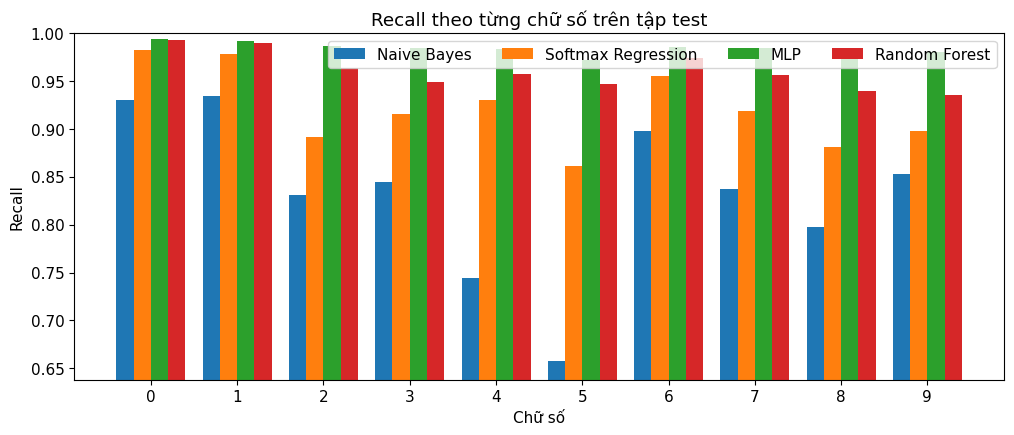

In [85]:
width = 0.2
fig, ax = plt.subplots(figsize=(12, 4.5))
for k, name in enumerate(MODEL_NAMES):
  ax.bar(np.arange(10) + (k - 1.5) * width, df_recall[name], width=width, label=name)

ax.set_xticks(range(10))
ax.set_ylim(df_recall.values.min() - 0.02, 1.0)
ax.set_xlabel("Chữ số")
ax.set_ylabel("Recall")
ax.set_title("Recall theo từng chữ số trên tập test")
ax.legend(ncol=4)
save_figure(fig, "recall_per_class")

### 10.5.1 Recall theo từng lớp chữ số

Lớp **5** có Recall thấp nhất trong mỗi mô hình được khảo sát; riêng Naive Bayes đạt **65,81%**. Đối với MLP, Recall theo lớp dao động từ **97,20%** (lớp 5) đến khoảng **99,39%** (lớp 0), cho thấy hiệu năng tương đối đồng đều nhưng không hoàn toàn như nhau giữa các chữ số.


## 10.6 K4. So sánh accuracy, thời gian và khả năng giải thích

Thời gian dự đoán đo trên cùng tập test 10.000 ảnh. Thời gian huấn luyện không gồm tải dữ liệu, vẽ hình và lưu file.

In [86]:
nb_final, sm_final = final_models["Naive Bayes"], final_models["Softmax Regression"]
rf_final = final_models["Random Forest"]
size_info = {
    "Naive Bayes": (sum(v.size for v in nb_final.means_.values()) + len(nb_final.priors_), np.nan, np.nan),
    "Softmax Regression": (sm_final.W.size + sm_final.b.size, np.nan, np.nan),
    "MLP": (n_parameters(mlp_final), np.nan, np.nan),
    "Random Forest": (np.nan, len(rf_final.trees), sum(t.tree_.node_count for t in rf_final.trees)),
}
interpretability = {
    "Naive Bayes": "Xác suất theo pixel của từng lớp đọc trực tiếp được (mục 6.4); giả định độc lập có điều kiện giữa các pixel.",
    "Softmax Regression": "Trọng số của từng lớp vẽ được thành ảnh 28x28 (mục 7.6); biên quyết định tuyến tính.",
    "MLP": "Nhiều lớp ẩn phi tuyến; không đọc trực tiếp ý nghĩa của từng trọng số.",
    "Random Forest": "Có độ quan trọng đặc trưng (mục 9.4); dự đoán là biểu quyết của nhiều cây.",
}
df_k4 = pd.DataFrame([{
    "Model": name, "train_time_s": fit_times[name], "predict_time_test_s": predict_time_test[name],
    "test_accuracy": final_metrics[(name, "test")]["accuracy"], "test_f1_macro": final_metrics[(name, "test")]["f1_macro"],
    "n_parameters": size_info[name][0], "n_trees": size_info[name][1], "total_tree_nodes": size_info[name][2],
    "interpretability": interpretability[name],
} for name in MODEL_NAMES])
save_table(df_k4, "final_comparison")

,Model,train_time_s,predict_time_test_s,test_accuracy,test_f1_macro,n_parameters,n_trees,total_tree_nodes,interpretability
0,Naive Bayes,0.0606,0.0252,0.8361,0.8346,7850.0000,NaN,NaN,Xác suất theo pixel của từng lớp đọc trực tiếp...
1,Softmax Regression,26.3259,0.0387,0.9222,0.9210,7850.0000,NaN,NaN,Trọng số của từng lớp vẽ được thành ảnh 28x28 ...
2,MLP,362.8098,0.2892,0.9847,0.9846,814090.0000,NaN,NaN,Nhiều lớp ẩn phi tuyến; không đọc trực tiếp ý ...
3,Random Forest,31.5295,0.4176,0.9610,0.9607,NaN,50.0000,339142.0000,Có độ quan trọng đặc trưng (mục 9.4); dự đoán ...


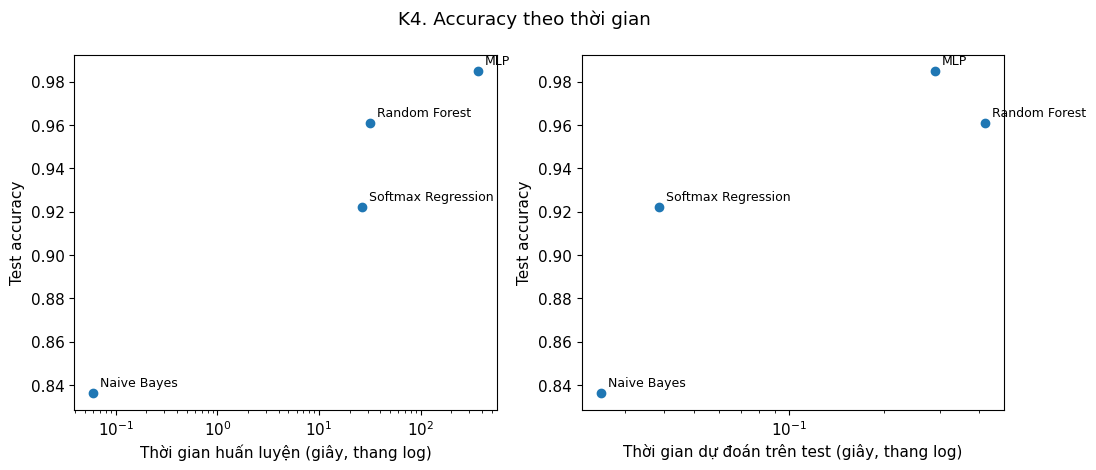

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, column, label in [(axes[0], "train_time_s", "Thời gian huấn luyện (giây, thang log)"),
                          (axes[1], "predict_time_test_s", "Thời gian dự đoán trên test (giây, thang log)")]:
  ax.scatter(df_k4[column], df_k4["test_accuracy"])
  for _, r in df_k4.iterrows():
    ax.annotate(r["Model"], (r[column], r["test_accuracy"]), textcoords="offset points", xytext=(5, 5), fontsize=9)
  ax.set_xscale("log")
  ax.set_xlabel(label)
  ax.set_ylabel("Test accuracy")

fig.suptitle("K4. Accuracy theo thời gian")
save_figure(fig, "accuracy_time")

### 10.6.1 Đánh đổi giữa độ chính xác, thời gian và khả năng giải thích (K4)

- **Naive Bayes:** Thời gian `fit()` khoảng **0,0565 giây** và Accuracy test **83,61%**; các tham số xác suất theo lớp tương đối dễ diễn giải.
- **Softmax Regression:** Thời gian `fit()` khoảng **24,01 giây**, Accuracy test **92,22%**; có thể trực quan hóa trọng số theo từng lớp.
- **Random Forest:** Thời gian `fit()` khoảng **31,00 giây**, Accuracy test **96,10%**; thời gian dự đoán 10.000 ảnh test khoảng **0,551 giây** và có thể khảo sát độ quan trọng đặc trưng.
- **MLP:** Thời gian `fit()` khoảng **306,96 giây**, Accuracy test **98,47%**; thời gian dự đoán 10.000 ảnh test khoảng **0,395 giây**. Mô hình có nhiều tham số và khó diễn giải trực tiếp hơn các mô hình tuyến tính.

Thời gian đo phụ thuộc phần cứng và cách triển khai; số liệu chỉ nên được so sánh trong cùng điều kiện thực nghiệm.


## 10.7 Lưu model cuối

Naive Bayes, Softmax Regression và Random Forest lưu bằng `joblib`. `MLPFromScratch` không kế thừa `nn.Module`, nên lưu `mlp_final.model.state_dict()` cùng cấu hình dùng để khởi tạo lại kiến trúc: `MLPFromScratch(**config).model.load_state_dict(state_dict)`.

In [88]:
joblib.dump(final_models["Naive Bayes"], ARTIFACT_DIR / "naive_bayes.joblib")
joblib.dump(final_models["Softmax Regression"], ARTIFACT_DIR / "softmax_regression.joblib")
joblib.dump(final_models["Random Forest"], ARTIFACT_DIR / "random_forest.joblib")
torch.save({"state_dict": mlp_final.model.state_dict(), "config": config_mlp}, ARTIFACT_DIR / "mlp.pt")
sorted(p.name for p in ARTIFACT_DIR.iterdir())

['cache',
 'mlp.pt',
 'naive_bayes.joblib',
 'random_forest.joblib',
 'softmax_regression.joblib']

# 11. Đối chiếu với các mô hình trong scikit-learn

Bốn mô hình đối chiếu được huấn luyện trên cùng tập train và sử dụng đặc trưng pixel trong khoảng [0, 1]. Các siêu tham số được chọn từ validation hoặc đối chiếu theo cấu hình cuối; tập test chỉ dùng để báo cáo. Việc so sánh nhằm kiểm tra mức hiệu năng tương đối, không yêu cầu hai cách triển khai cho ra cùng trọng số.

**Các khác biệt khi diễn giải kết quả:**

- **Softmax Regression và `LogisticRegression`:** Quy ước hệ số điều chuẩn, hàm mục tiêu và phương pháp tối ưu khác nhau. Tham số `C` được chọn riêng bằng validation; không coi `C` tương đương trực tiếp với `lam`.
- **MLP và `MLPClassifier`:** Khác cách khởi tạo, điều chuẩn và cơ chế Dropout; vì vậy không thể quy chênh lệch Accuracy cho riêng Dropout.
- **Random Forest và `RandomForestClassifier`:** Cách tổng hợp dự đoán khác nhau: mô hình của nhóm dùng biểu quyết đa số, còn mô hình scikit-learn tổng hợp xác suất của các cây.
- **Thời gian MLP:** Giá trị `fit_time_s` của mô hình nhóm gồm cả các lần đánh giá train/validation trong quá trình huấn luyện.


In [89]:
def fit_timed(model):
  return fit_model_cached(model, (X_train, y_train), tag="sklearn")

def library_result(model, fit_time):
  start = time.perf_counter()
  y_pred_test = model.predict(X_test)
  predict_time = time.perf_counter() - start
  val_metrics = compute_classification_metrics(y_val, model.predict(X_val))
  test_metrics = compute_classification_metrics(y_test, y_pred_test)
  return {"implementation": "sklearn", "model_class": type(model).__name__,
            "val_accuracy": val_metrics["accuracy"], "test_accuracy": test_metrics["accuracy"],
            "test_f1_macro": test_metrics["f1_macro"], "train_time_s": fit_time, "predict_time_test_s": predict_time}

library_results = {}

## 11.1 Naive Bayes và `MultinomialNB`

In [90]:
sk_nb_final = MultinomialNB(alpha=config_nb["alpha"])
library_results["Naive Bayes"] = library_result(sk_nb_final, fit_timed(sk_nb_final))

[CACHE SAVED] MultinomialNB / sklearn (0.3s)


## 11.2 Softmax Regression và `LogisticRegression` (multinomial)

`LogisticRegression` với solver `lbfgs` mặc định dùng hàm mất mát multinomial cho bài toán nhiều lớp. `C` chọn theo validation accuracy.

In [91]:
LOGREG_CS = [0.01, 0.1, 1.0, 10.0]
logreg_models, rows = {}, []
for C in LOGREG_CS:
  model = LogisticRegression(C=C, max_iter=1000)
  fit_time = fit_timed(model)
  logreg_models[C] = (model, fit_time)
  rows.append({"C": C, "val_accuracy": accuracy_score(y_val, model.predict(X_val)),
               "train_time_s": fit_time, "n_iter": int(model.n_iter_[0])})
df_logreg_c = pd.DataFrame(rows)
best_C = float(df_logreg_c.loc[df_logreg_c["val_accuracy"].idxmax(), "C"])
print("C tốt nhất theo validation accuracy:", best_C)
save_table(df_logreg_c, "sklearn_logreg_C")

library_results["Softmax Regression"] = library_result(*logreg_models[best_C])

[CACHE SAVED] LogisticRegression / sklearn (35.7s)
[CACHE SAVED] LogisticRegression / sklearn (45.7s)
[CACHE SAVED] LogisticRegression / sklearn (96.9s)
[CACHE SAVED] LogisticRegression / sklearn (164.8s)
C tốt nhất theo validation accuracy: 1.0


## 11.3 MLP và `MLPClassifier`

In [92]:
with warnings.catch_warnings():
  # Số epoch cố định nên sklearn báo chưa hội tụ; cảnh báo này được bỏ qua có chủ đích
  warnings.simplefilter("ignore", ConvergenceWarning)
  sk_mlp = MLPClassifier(
      hidden_layer_sizes=tuple(config_mlp["hidden_sizes"]), activation="relu", solver="sgd",
      learning_rate="constant", learning_rate_init=config_mlp["lr"], momentum=config_mlp["momentum"],
      nesterovs_momentum=False, batch_size=config_mlp["batch_size"], alpha=config_mlp["weight_decay"],
      max_iter=mlp_final.best_epoch_, tol=0.0, n_iter_no_change=mlp_final.best_epoch_, random_state=SEED)
  sk_mlp_fit_time = fit_timed(sk_mlp)
library_results["MLP"] = library_result(sk_mlp, sk_mlp_fit_time)

[CACHE SAVED] MLPClassifier / sklearn (218.5s)


## 11.4 Random Forest và `RandomForestClassifier`

`n_jobs` để mặc định (một luồng) để thời gian so sánh được với bản tự viết.

In [93]:
sk_rf_final = RandomForestClassifier(n_estimators=config_forest["n_estimators"], max_depth=config_forest["max_depth"],
                                     max_features="sqrt", bootstrap=True, random_state=SEED)
library_results["Random Forest"] = library_result(sk_rf_final, fit_timed(sk_rf_final))

[CACHE SAVED] RandomForestClassifier / sklearn (20.8s)


## 11.5 K5. Bảng đối chiếu bốn cặp model

In [94]:
rows = []
for name in MODEL_NAMES:
  rows.append({"pair": name, "implementation": "Tự viết", "model_class": type(final_models[name]).__name__,
               "val_accuracy": final_metrics[(name, "validation")]["accuracy"],
               "test_accuracy": final_metrics[(name, "test")]["accuracy"],
               "test_f1_macro": final_metrics[(name, "test")]["f1_macro"],
               "train_time_s": fit_times[name], "predict_time_test_s": predict_time_test[name]})
  rows.append({"pair": name, **library_results[name]})
df_k5 = pd.DataFrame(rows)
save_table(df_k5, "sklearn_comparison")

,pair,implementation,model_class,val_accuracy,test_accuracy,test_f1_macro,train_time_s,predict_time_test_s
0,Naive Bayes,Tự viết,NaiveBayes,0.8257,0.8361,0.8346,0.0606,0.0252
1,Naive Bayes,sklearn,MultinomialNB,0.8257,0.8361,0.8346,0.3126,0.0529
2,Softmax Regression,Tự viết,SoftmaxRegression,0.9187,0.9222,0.9210,26.3259,0.0387
3,Softmax Regression,sklearn,LogisticRegression,0.9214,0.9241,0.9230,96.9313,0.0607
4,MLP,Tự viết,MLPFromScratch,0.9832,0.9847,0.9846,362.8098,0.2892
5,MLP,sklearn,MLPClassifier,0.9826,0.9835,0.9834,218.4906,0.2980
6,Random Forest,Tự viết,RandomForestFromScratch,0.9594,0.9610,0.9607,31.5295,0.4176
7,Random Forest,sklearn,RandomForestClassifier,0.9617,0.9622,0.9619,20.7983,0.1713


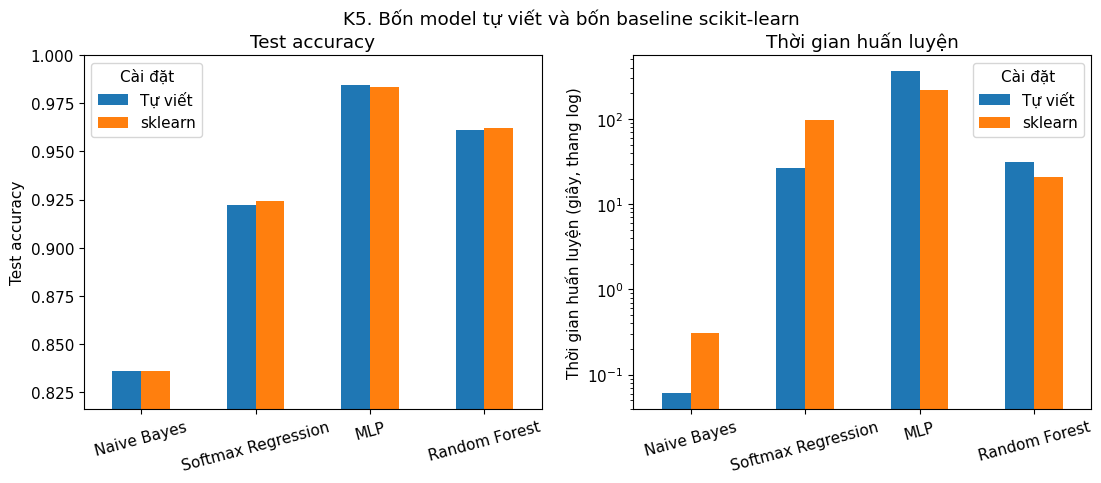

In [95]:
acc_pivot = df_k5.pivot(index="pair", columns="implementation", values="test_accuracy").loc[MODEL_NAMES]
time_pivot = df_k5.pivot(index="pair", columns="implementation", values="train_time_s").loc[MODEL_NAMES]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
acc_pivot.plot(kind="bar", ax=axes[0])
axes[0].set_ylim(acc_pivot.values.min() - 0.02, 1.0)
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test accuracy")
time_pivot.plot(kind="bar", ax=axes[1], logy=True)
axes[1].set_ylabel("Thời gian huấn luyện (giây, thang log)")
axes[1].set_title("Thời gian huấn luyện")
for ax in axes:
  ax.set_xlabel("")
  ax.tick_params(axis="x", rotation=15)
  ax.legend(title="Cài đặt")

fig.suptitle("K5. Bốn model tự viết và bốn baseline scikit-learn")
save_figure(fig, "sklearn_comparison")

### 11.5.1 Đối chiếu kết quả với scikit-learn (K5)

Trên tập test, Accuracy của các cặp mô hình lần lượt là:

- **Naive Bayes:** Nhóm cài đặt **83,61%**; scikit-learn **83,61%**.
- **Softmax Regression:** Nhóm cài đặt **92,22%**; `LogisticRegression` **92,41%**.
- **MLP:** Nhóm cài đặt **98,47%**; `MLPClassifier` **98,35%**.
- **Random Forest:** Nhóm cài đặt **96,10%**; `RandomForestClassifier` **96,22%**.

Các sai khác nhỏ cho thấy kết quả của các cách triển khai tương đối gần nhau trên MNIST. Tuy nhiên, do có khác biệt về cách tối ưu, điều chuẩn và tổng hợp dự đoán, không thể quy chênh lệch cho một yếu tố duy nhất hoặc kết luận mô hình nào luôn tốt hơn trong mọi điều kiện.


# 12. Tổng hợp và kiểm tra Notebook

## 12.1 Cấu hình cuối và môi trường

In [96]:
display(df_final_config)
df_env = pd.DataFrame(list({
    "Python": platform.python_version(), "NumPy": np.__version__, "PyTorch": torch.__version__,
    "scikit-learn": sklearn.__version__, "seed": SEED, "train_size": len(X_train),
    "validation_size": len(X_val), "test_size": len(X_test),
    "file_pytest": str(TEST_FILE.relative_to(PROJECT_ROOT)),
}.items()), columns=["item", "value"])
save_table(df_env, "environment")

,model,config,fit_time_s
0,Naive Bayes,"{""alpha"": 0.001}",0.0606
1,Softmax Regression,"{""lr"": 0.1, ""max_epochs"": 20, ""batch_size"": 12...",26.3259
2,MLP,"{""hidden_sizes"": [1024], ""lr"": 0.1, ""momentum""...",362.8098
3,Random Forest,"{""n_estimators"": 50, ""max_depth"": 15, ""max_fea...",31.5295


,item,value
0,Python,3.13.18
1,NumPy,2.4.6
2,PyTorch,2.14.1+cpu
3,scikit-learn,1.6.1
4,seed,42
5,train_size,50000
6,validation_size,10000
7,test_size,10000
8,file_pytest,tests/test_models.py


### 12.1.1 Tổng hợp cấu hình và môi trường

Bảng trên ghi lại siêu tham số cuối cùng, thời gian `fit()` và phiên bản môi trường thực nghiệm. Các kết quả và mô hình được lưu vào thư mục đầu ra trên Google Drive. Việc lưu thông tin cấu hình hỗ trợ tái lập thí nghiệm, nhưng không bảo đảm kết quả hoặc thời gian chạy sẽ trùng khớp tuyệt đối trên mọi môi trường.


## 12.2 Danh mục thí nghiệm và file kết quả

Bảng liệt kê **31 mục kiểm thử, khảo sát và đánh giá** cùng các đường dẫn đầu ra dự kiến dưới thư mục `OUTPUT_ROOT`.

In [97]:
toc = [
    ("Unit test", "Chạy test_models.py bằng pytest (12 test)", "4", ["results/unit_tests.csv"]),
    ("E1", "Lưới ảnh ví dụ theo nhãn", "3.1", ["figures/eda_sample_grid.png"]),
    ("E2", "Phân bố lớp trên train, validation, test", "3.2", ["figures/eda_class_distribution.png", "results/eda_class_distribution.csv"]),
    ("E3", "Cường độ pixel và độ lệch chuẩn", "3.3", ["figures/eda_pixel_statistics.png", "results/eda_pixel_statistics.csv"]),
    ("E4", "Ảnh trung bình và tổng cường độ pixel theo lớp", "3.4", ["figures/eda_class_means.png", "results/eda_class_intensity.csv"]),
    ("E5", "Khoảng cách giữa các ảnh trung bình, ba cặp gần nhất", "3.5", ["figures/eda_centroid_distance.png", "results/eda_closest_pairs.csv"]),
    ("P1", "Sơ đồ quy trình thực nghiệm", "5.1", ["figures/diagram_pipeline.png"]),
    ("P2", "Sơ đồ kiến trúc MLP", "5.2", ["figures/diagram_mlp.png"]),
    ("P3", "Sơ đồ Random Forest", "5.3", ["figures/diagram_random_forest.png"]),
    ("N1", "Naive Bayes: sweep alpha", "6.3", ["figures/nb_alpha_sweep.png", "results/nb_alpha_sweep.csv"]),
    ("S1", "Softmax: mất mát theo epoch", "7.2", ["figures/softmax_loss_curve.png"]),
    ("S2", "Softmax: sweep learning rate", "7.3", ["figures/softmax_lr_sweep.png", "results/softmax_lr_sweep.csv"]),
    ("S3", "Softmax: sweep L2", "7.4", ["figures/softmax_l2_sweep.png", "results/softmax_l2_sweep.csv"]),
    ("P4", "Softmax: heatmap trọng số", "7.6", ["figures/softmax_weights.png"]),
    ("M0", "MLP: baseline", "8.1", ["results/mlp_baseline.csv"]),
    ("M1", "MLP: đường cong học", "8.2", ["figures/mlp_learning_curve.png"]),
    ("M2", "MLP: learning rate x momentum", "8.3", ["figures/mlp_lr_momentum.png", "results/mlp_lr_momentum.csv"]),
    ("M3", "MLP: batch size", "8.4", ["figures/mlp_batch_size.png", "results/mlp_batch_size.csv"]),
    ("M4", "MLP: kiến trúc", "8.5", ["figures/mlp_architecture.png", "results/mlp_architecture.csv"]),
    ("M5", "MLP: Dropout", "8.6", ["figures/mlp_dropout.png", "results/mlp_dropout.csv"]),
    ("M6", "MLP: Early Stopping", "8.7", ["figures/mlp_early_stopping.png", "results/mlp_early_stopping.csv"]),
    ("M7", "MLP: L2 Weight Decay", "8.8", ["figures/mlp_weight_decay.png", "results/mlp_weight_decay.csv"]),
    ("R1", "Random Forest: số cây", "9.2", ["figures/forest_n_estimators.png", "results/forest_n_estimators.csv"]),
    ("R2", "Decision Tree đơn và Random Forest", "9.3", ["results/forest_tree_vs_forest.csv"]),
    ("R3", "Random Forest: độ quan trọng đặc trưng", "9.4", ["figures/forest_feature_importance.png"]),
    ("K1", "Metrics của 4 model trên 3 tập", "10.2", ["results/final_metrics.csv"]),
    ("K2", "Mười hai ma trận nhầm lẫn", "10.3", ["results/confusion_matrices.npz", "figures/confusion_matrices_test.png"]),
    ("K3", "Cặp chữ số nhầm lẫn nhiều nhất, ảnh dự đoán sai", "10.4", ["results/confusion_pairs.csv", "figures/confusion_top_pairs.png", "figures/misclassified_examples.png"]),
    ("Recall", "Recall theo chữ số", "10.5", ["results/recall_per_class.csv", "figures/recall_per_class.png"]),
    ("K4", "So sánh accuracy, thời gian, khả năng giải thích", "10.6", ["results/final_comparison.csv", "figures/accuracy_time.png"]),
    ("K5", "Đối chiếu với scikit-learn", "11.5", ["results/sklearn_comparison.csv", "figures/sklearn_comparison.png"]),
]
df_toc = pd.DataFrame([
    {"id": exp_id, "content": content, "section": section, "outputs": ", ".join(files),
     "output_exists": all((OUTPUT_ROOT / f).exists() for f in files)}
    for exp_id, content, section, files in toc
])
save_table(df_toc, "experiment_index")

,id,content,section,outputs,output_exists
0,Unit test,Chạy test_models.py bằng pytest (12 test),4,results/unit_tests.csv,True
1,E1,Lưới ảnh ví dụ theo nhãn,3.1,figures/eda_sample_grid.png,True
2,E2,"Phân bố lớp trên train, validation, test",3.2,"figures/eda_class_distribution.png, results/ed...",True
3,E3,Cường độ pixel và độ lệch chuẩn,3.3,"figures/eda_pixel_statistics.png, results/eda_...",True
4,E4,Ảnh trung bình và tổng cường độ pixel theo lớp,3.4,"figures/eda_class_means.png, results/eda_class...",True
5,E5,"Khoảng cách giữa các ảnh trung bình, ba cặp gầ...",3.5,"figures/eda_centroid_distance.png, results/eda...",True
6,P1,Sơ đồ quy trình thực nghiệm,5.1,figures/diagram_pipeline.png,True
7,P2,Sơ đồ kiến trúc MLP,5.2,figures/diagram_mlp.png,True
8,P3,Sơ đồ Random Forest,5.3,figures/diagram_random_forest.png,True
9,N1,Naive Bayes: sweep alpha,6.3,"figures/nb_alpha_sweep.png, results/nb_alpha_s...",True


### 12.2.1 Diễn giải danh mục thí nghiệm

Danh mục trên liệt kê các đầu ra dự kiến cho từng mục. Cột `output_exists` kiểm tra sự tồn tại của từng file theo đường dẫn `OUTPUT_ROOT` (thư mục kết quả trên Google Drive khi chạy Colab) tại thời điểm chạy cell: giá trị `True` nghĩa là toàn bộ file dự kiến của mục đó đã có trong thư mục đầu ra. Giá trị này chỉ xác nhận file tồn tại, không xác nhận nội dung file đúng. Mục 12.4 liệt kê các file thực tế có trong thư mục đầu ra.


## 12.3 Tổng hợp tự động từ các bảng kết quả

Các bảng tiếp theo được tạo từ dữ liệu kết quả đã tính trong Notebook. Khi diễn giải, cần phân biệt Accuracy trên train, validation và test, cũng như sự khác nhau giữa thời gian `fit()` và thời gian huấn luyện thuần của MLP.


In [98]:
k4 = df_k4.set_index("Model")
df_overview = pd.DataFrame({
    "criterion": ["Test accuracy cao nhất", "Test macro-F1 cao nhất",
                  "Thời gian huấn luyện ngắn nhất", "Thời gian dự đoán trên test ngắn nhất"],
    "model": [k4["test_accuracy"].idxmax(), k4["test_f1_macro"].idxmax(),
              k4["train_time_s"].idxmin(), k4["predict_time_test_s"].idxmin()],
    "value": [k4["test_accuracy"].max(), k4["test_f1_macro"].max(),
              k4["train_time_s"].min(), k4["predict_time_test_s"].min()],
})
save_table(df_overview, "summary_overview")

acc_table = df_k1.pivot(index="Model", columns="Split", values="Accuracy").loc[MODEL_NAMES, SPLIT_NAMES]
df_gap = acc_table.assign(gap_train_validation=acc_table["train"] - acc_table["validation"],
                          gap_train_test=acc_table["train"] - acc_table["test"])
save_table(df_gap, "summary_gap", index=True)

Split,train,validation,test,gap_train_validation,gap_train_test
Model,,,,,
Naive Bayes,0.8243,0.8257,0.8361,-0.0014,-0.0118
Softmax Regression,0.9241,0.9187,0.9222,0.0054,0.0019
MLP,0.9998,0.9832,0.9847,0.0166,0.0151
Random Forest,0.9967,0.9594,0.9610,0.0373,0.0357


## 12.4 Danh sách file đã lưu

In [99]:
df_saved = pd.DataFrame([
    {"folder": d.name, "file": p.name, "size_kb": p.stat().st_size / 1024}
    for d in (RESULT_DIR, FIG_DIR, ARTIFACT_DIR) for p in sorted(d.iterdir())
])
df_saved

,folder,file,size_kb
0,results,confusion_matrices.npz,12.5742
1,results,confusion_pairs.csv,0.4707
2,results,data_split_summary.csv,0.1973
3,results,eda_centroid_distance.csv,0.9219
4,results,eda_class_distribution.csv,0.4492
...,...,...,...
80,artifacts,cache,4.0000
81,artifacts,mlp.pt,3182.4268
82,artifacts,naive_bayes.joblib,32.0479
83,artifacts,random_forest.joblib,47714.7744


## 12.5 Nhận xét tổng hợp

Thực nghiệm xây dựng và đánh giá bốn phương pháp phân lớp trên cùng bộ dữ liệu MNIST và cùng quy tắc chia tập. Trong các cấu hình được khảo sát, MLP đạt Accuracy test cao nhất (**98,47%**), tiếp theo là Random Forest (**96,10%**), Softmax Regression (**92,22%**) và Naive Bayes (**83,61%**). Kết quả đối chiếu với scikit-learn giúp kiểm tra tính hợp lý của hiệu năng thu được. Phạm vi tự cài đặt khác nhau giữa các phương pháp; riêng Random Forest sử dụng cây quyết định cơ sở từ scikit-learn. Các kết luận cần được giới hạn trong thiết lập thực nghiệm đã thực hiện.


## 12.6 Giới hạn và hướng phát triển

**Giới hạn:**

1. MLP hiện xử lý trên CPU; thời gian huấn luyện có thể lớn khi khảo sát nhiều cấu hình.
2. Các mô hình sử dụng vector pixel 784 chiều, chưa khai thác trực tiếp cấu trúc không gian hai chiều của ảnh như mạng tích chập.
3. Random Forest sử dụng `DecisionTreeClassifier` của scikit-learn làm cây cơ sở; phần tự cài đặt tập trung vào bootstrap và biểu quyết.
4. Việc chọn siêu tham số được thực hiện qua các thí nghiệm riêng lẻ, chưa bao quát toàn bộ tổ hợp và chưa đánh giá độ biến thiên qua nhiều seed.

**Hướng phát triển:** Khảo sát mô hình CNN, lặp lại thí nghiệm với nhiều seed và mở rộng đánh giá sang các bộ dữ liệu chữ số hoặc ký tự viết tay khác.
